# 🕐 Tarea: Series de Tiempo con LSTM y GRU — Energía Solar y Precio del Cobre

**Curso:** IS056B — Ingeniería del Conocimiento | UNCP 2026-II
**Unidad II:** Transferencia de Aprendizaje, Series de Tiempo y MLOps
**Basado en:** Sesión 10-A — Series de Tiempo con RNN, LSTM y GRU
**Integrante:** _Huaman Guizgueta Fernando Jesus_

---

### Objetivo
Aplicar y comparar las arquitecturas recurrentes **LSTM** y **GRU** en **dos datasets distintos** de series de tiempo, siguiendo el mismo flujo de trabajo de la Sesión 10-A: exploración, preprocesamiento, ventanas deslizantes, modelos, evaluación contra baseline naive y experimento de tamaño de ventana.

### Estructura del Notebook
| # | Dataset | Frecuencia | Tarea | Modelos |
|---|---|---|---|---|
| 1 | ☀️ Generación de energía solar (Kaggle, Planta 1) | 15 minutos | **Forecasting multivariado** de la potencia AC | LSTM vs GRU |
| 2 | 🔶 Precio del cobre (COMEX, `HG=F`) | Diaria | **Forecasting multivariado** del precio de cierre | LSTM vs GRU |
> **Datos:** ambos datasets se leen desde la carpeta `/content/data` de Colab.
> **Dataset 1:** Se usa `Plant_1_Generation_Data.csv` y `Plant_1_Weather_Sensor_Data.csv` (Kaggle: *Solar Power Generation Data*).
> **Dataset 2:** si `/content/data/cobre_HGF.csv` no existe, se descarga con `yfinance` y se guarda ahí automáticamente.

In [ ]:
!pip install -q statsmodels yfinance

import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, callbacks
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             mean_absolute_error, mean_squared_error)
import time
import warnings
warnings.filterwarnings('ignore')

# Reproducibilidad
np.random.seed(42)
tf.random.set_seed(42)

# Estilo de visualización
sns.set_style('darkgrid')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 12

print(f'TensorFlow: {tf.__version__}')
print(f'NumPy: {np.__version__}')
print(f'Pandas: {pd.__version__}')

TensorFlow: 2.21.0
NumPy: 2.4.6
Pandas: 2.2.3


In [ ]:
# ============================================================
# 🖥️ Verificación de GPU
# ============================================================
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f'GPU disponible: {gpus[0].name}')
    print(f'   Nombre: {tf.test.gpu_device_name()}')
else:
    print('No se detectó GPU. El entrenamiento será más lento.')
    print(' Ve a: Entorno de ejecución → Cambiar tipo de entorno → GPU T4')

GPU disponible: /physical_device:GPU:0
   Nombre: /device:GPU:0


## 📋 Recapitulación: RNN vs LSTM vs GRU

| Característica | RNN Simple | LSTM | GRU |
|---|---|---|---|
| **Compuertas** | Ninguna | 3 (Forget, Input, Output) | 2 (Update, Reset) |
| **Estados** | 1 ($h_t$) | 2 ($h_t$ + $C_t$) | 1 ($h_t$) |
| **Vanishing Gradient** | ❌ Severo | ✅ Resuelto | ✅ Resuelto |
| **Secuencias largas** | ~10-20 pasos | ~200+ pasos | ~200+ pasos |
| **Parámetros (64 units)** | ~4K | ~17K | ~13K |
| **Velocidad** | Rápida | Lenta | Intermedia |
| **Mejor para** | Nunca (usar LSTM/GRU) | Secuencias largas, estándar | Recursos limitados |

> **Regla práctica:** Empieza con GRU (más rápido), escala a LSTM si necesitas más capacidad.

In [ ]:
# ============================================================
# 🛠️ Funciones auxiliares
# ============================================================

def create_sequences(data, window_size, horizon=1):
    '''Crea pares (X, y) con ventanas deslizantes.

    Args:
        data: array 1D o 2D (samples, features)
        window_size: pasos temporales de entrada
        horizon: pasos a predecir

    Returns:
        X: array (n_samples, window_size, features)
        y: array (n_samples, horizon) o (n_samples,) si horizon=1
    '''
    if data.ndim == 1:
        data = data.reshape(-1, 1)

    X, y = [], []
    for i in range(len(data) - window_size - horizon + 1):
        X.append(data[i:i + window_size])
        y.append(data[i + window_size:i + window_size + horizon, 0])
    X = np.array(X)
    y = np.array(y)
    if horizon == 1:
        y = y.flatten()
    return X, y


def plot_training_history(history, title='Curvas de Entrenamiento'):
    '''Grafica loss y métricas de un entrenamiento.'''
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Loss
    axes[0].plot(history.history['loss'], label='Train Loss', linewidth=2)
    axes[0].plot(history.history['val_loss'], label='Val Loss', linewidth=2)
    axes[0].set_xlabel('Época')
    axes[0].set_ylabel('Loss (MSE)')
    axes[0].set_title(f'{title} — Loss')
    axes[0].legend()

    # MAE si está disponible
    mae_key = 'mae' if 'mae' in history.history else 'accuracy'
    val_mae_key = 'val_mae' if 'val_mae' in history.history else 'val_accuracy'
    label = 'MAE' if 'mae' in history.history else 'Accuracy'

    if mae_key in history.history:
        axes[1].plot(history.history[mae_key], label=f'Train {label}', linewidth=2)
        axes[1].plot(history.history[val_mae_key], label=f'Val {label}', linewidth=2)
        axes[1].set_xlabel('Época')
        axes[1].set_ylabel(label)
        axes[1].set_title(f'{title} — {label}')
        axes[1].legend()

    plt.tight_layout()
    plt.show()


def evaluate_forecast(y_true, y_pred):
    '''Calcula métricas de pronóstico.'''
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    # MAPE: evitar división por cero
    mask = y_true != 0
    mape = np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100
    return {'MAE': mae, 'RMSE': rmse, 'MAPE': mape}
# Paleta de colores consistente
COLORS = {
    'lstm': '#2196F3',
    'gru': '#FF9800',
    'rnn': '#F44336',
    'bilstm': '#4CAF50',
    'actual': '#263238',
    'naive': '#9E9E9E',
    'pred': '#E91E63'
}

print('✅ Funciones auxiliares cargadas')

✅ Funciones auxiliares cargadas


---

## ☀️ Dataset 1: Generación de Energía Solar — LSTM vs GRU

**Objetivo:** Comparar LSTM y GRU para pronosticar la **potencia AC total** de una planta solar un paso adelante (15 minutos), usando también variables del clima como entrada.

**Dataset:** [Solar Power Generation Data](https://www.kaggle.com/datasets/anikannal/solar-power-generation-data) (Kaggle) — Planta 1: generación de 22 inversores y sensores meteorológicos, medidos cada 15 minutos durante ~34 días.

**Tarea:** Forecasting multivariado (many-to-one)

**Pasos:**
1. Exploración y descomposición de la serie
2. Análisis de correlación entre variables
3. Preprocesamiento: regularización temporal, split cronológico, normalización
4. Creación de ventanas deslizantes
5. Modelos LSTM y GRU (apilados) + referencias univariadas
6. Evaluación contra baseline naive
7. Experimento de tamaño de ventana

In [ ]:
# 📥 Carga del dataset Solar Power Generation (Planta 1)
import os
import shutil
from google.colab import files
DATA_DIR = '/content/data'
os.makedirs(DATA_DIR, exist_ok=True)
archivos_solar = ['Plant_1_Generation_Data.csv', 'Plant_1_Weather_Sensor_Data.csv']
faltan = [f for f in archivos_solar if not os.path.exists(os.path.join(DATA_DIR, f))]
if faltan:
    print(f'Faltan en {DATA_DIR}: {faltan}')
    print('Súbelos ahora (se moverán solos a /content/data), o arrástralos a la carpeta data del panel izquierdo.')
    for nombre in files.upload():
        shutil.move(nombre, os.path.join(DATA_DIR, nombre))
else:
    print(f'✅ Archivos encontrados en {DATA_DIR}')

# Generación: una fila por inversor y por instante (22 inversores)
gen = pd.read_csv(os.path.join(DATA_DIR, 'Plant_1_Generation_Data.csv'))
gen['DATE_TIME'] = pd.to_datetime(gen['DATE_TIME'], dayfirst=True)   # formato dd-mm-aaaa

# Clima: una fila por instante
weather = pd.read_csv(os.path.join(DATA_DIR, 'Plant_1_Weather_Sensor_Data.csv'))
weather['DATE_TIME'] = pd.to_datetime(weather['DATE_TIME'])

print(f'Generación: {gen.shape} | {gen["DATE_TIME"].min()} → {gen["DATE_TIME"].max()}')
print(f'Clima:      {weather.shape} | {weather["DATE_TIME"].min()} → {weather["DATE_TIME"].max()}')
print(f'Inversores: {gen["SOURCE_KEY"].nunique()}')

# Potencia AC total de la planta = suma de todos los inversores en cada instante
ac_total = gen.groupby('DATE_TIME')['AC_POWER'].sum()
clima = weather.set_index('DATE_TIME')[['AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'IRRADIATION']]

# Unir y regularizar a 15 minutos (rellenar huecos por interpolación)
df_solar = pd.concat([ac_total, clima], axis=1).resample('15min').mean()
n_huecos = int(df_solar.isna().any(axis=1).sum())
df_solar = df_solar.interpolate(limit_direction='both')

print(f'\nShape final: {df_solar.shape} | Huecos interpolados: {n_huecos} | NaN restantes: {int(df_solar.isna().sum().sum())}')
print(f'Frecuencia: cada 15 minutos')
print(f'\nColumnas disponibles ({len(df_solar.columns)}):')
for col in df_solar.columns:
    print(f'  • {col}')

df_solar.head()


📤 Faltan en /content/data: ['Plant_1_Generation_Data.csv', 'Plant_1_Weather_Sensor_Data.csv']
   Súbelos ahora (se moverán solos a /content/data), o arrástralos a la carpeta data del panel izquierdo.


Saving Plant_1_Generation_Data.csv to Plant_1_Generation_Data.csv
Saving Plant_1_Weather_Sensor_Data.csv to Plant_1_Weather_Sensor_Data.csv
Generación: (68778, 7) | 2020-05-15 00:00:00 → 2020-06-17 23:45:00
Clima:      (3182, 6) | 2020-05-15 00:00:00 → 2020-06-17 23:45:00
Inversores: 22

Shape final: (3264, 4) | Huecos interpolados: 107 | NaN restantes: 0
Frecuencia: cada 15 minutos

Columnas disponibles (4):
  • AC_POWER
  • AMBIENT_TEMPERATURE
  • MODULE_TEMPERATURE
  • IRRADIATION


,AC_POWER,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
DATE_TIME,,,,
2020-05-15 00:00:00,0.0,25.184316,22.857507,0.0
2020-05-15 00:15:00,0.0,25.084589,22.761668,0.0
2020-05-15 00:30:00,0.0,24.935753,22.592306,0.0
2020-05-15 00:45:00,0.0,24.846130,22.360852,0.0
2020-05-15 01:00:00,0.0,24.621525,22.165423,0.0


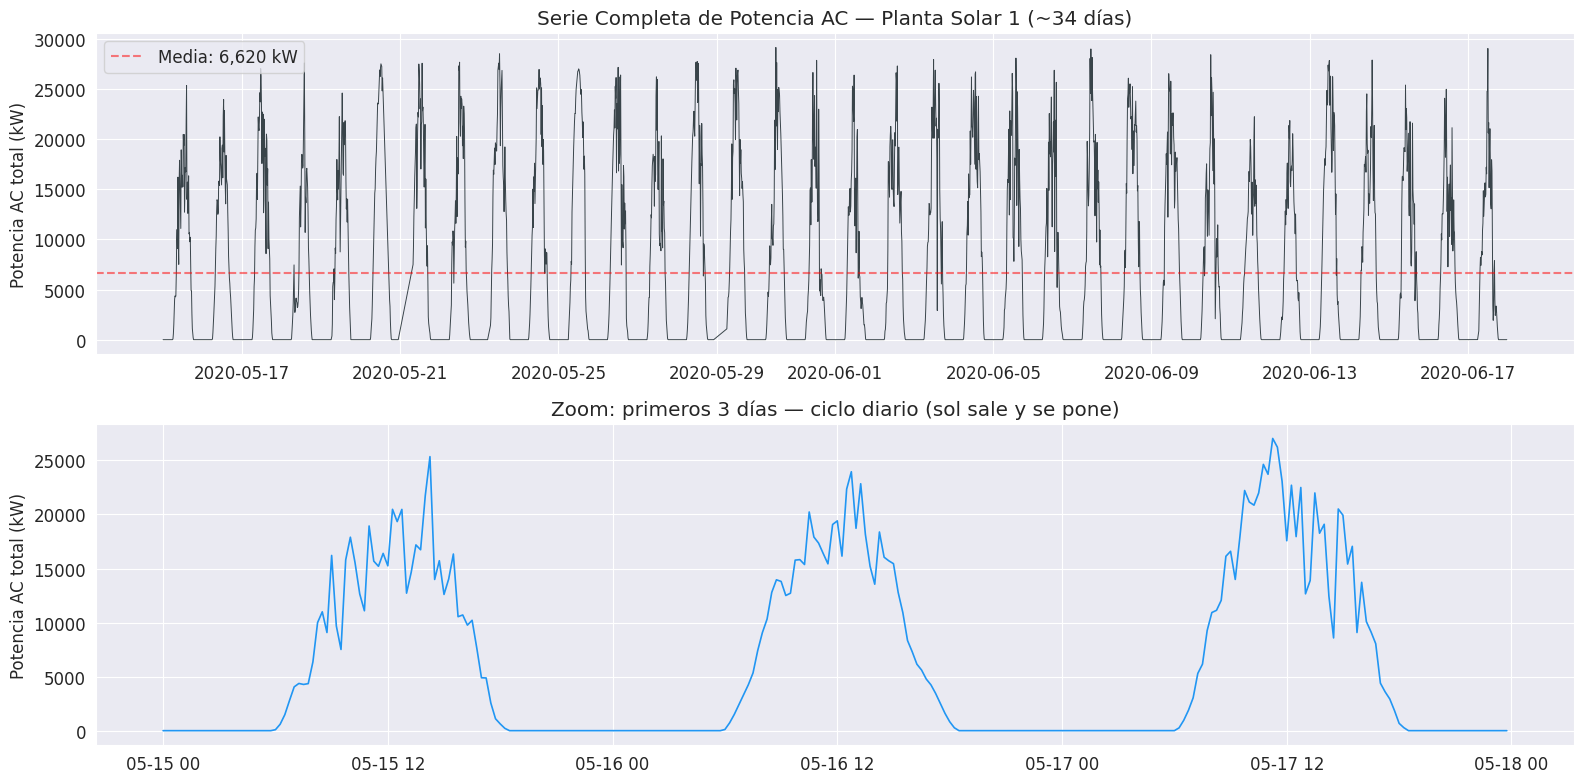

Estadísticas de potencia AC total:
  Mínima: 0 kW | Máxima: 29,150 kW | Media: 6,620 kW


In [ ]:
# ============================================================
# 📈 Visualización de la serie completa de potencia AC
# ============================================================
fig, axes = plt.subplots(2, 1, figsize=(16, 8))

ac = df_solar['AC_POWER']

axes[0].plot(ac.index, ac.values, linewidth=0.7, color=COLORS['actual'], alpha=0.9)
axes[0].axhline(y=ac.mean(), color='red', linestyle='--', alpha=0.5,
                label=f'Media: {ac.mean():,.0f} kW')
axes[0].set_ylabel('Potencia AC total (kW)')
axes[0].set_title('Serie Completa de Potencia AC — Planta Solar 1 (~34 días)')
axes[0].legend()

# Zoom: 3 días (96 pasos por día)
zoom = ac.iloc[:96 * 3]
axes[1].plot(zoom.index, zoom.values, linewidth=1.2, color=COLORS['lstm'])
axes[1].set_ylabel('Potencia AC total (kW)')
axes[1].set_title('Zoom: primeros 3 días — ciclo diario (sol sale y se pone)')

plt.tight_layout()
plt.show()

print(f'Estadísticas de potencia AC total:')
print(f'  Mínima: {ac.min():,.0f} kW | Máxima: {ac.max():,.0f} kW | Media: {ac.mean():,.0f} kW')


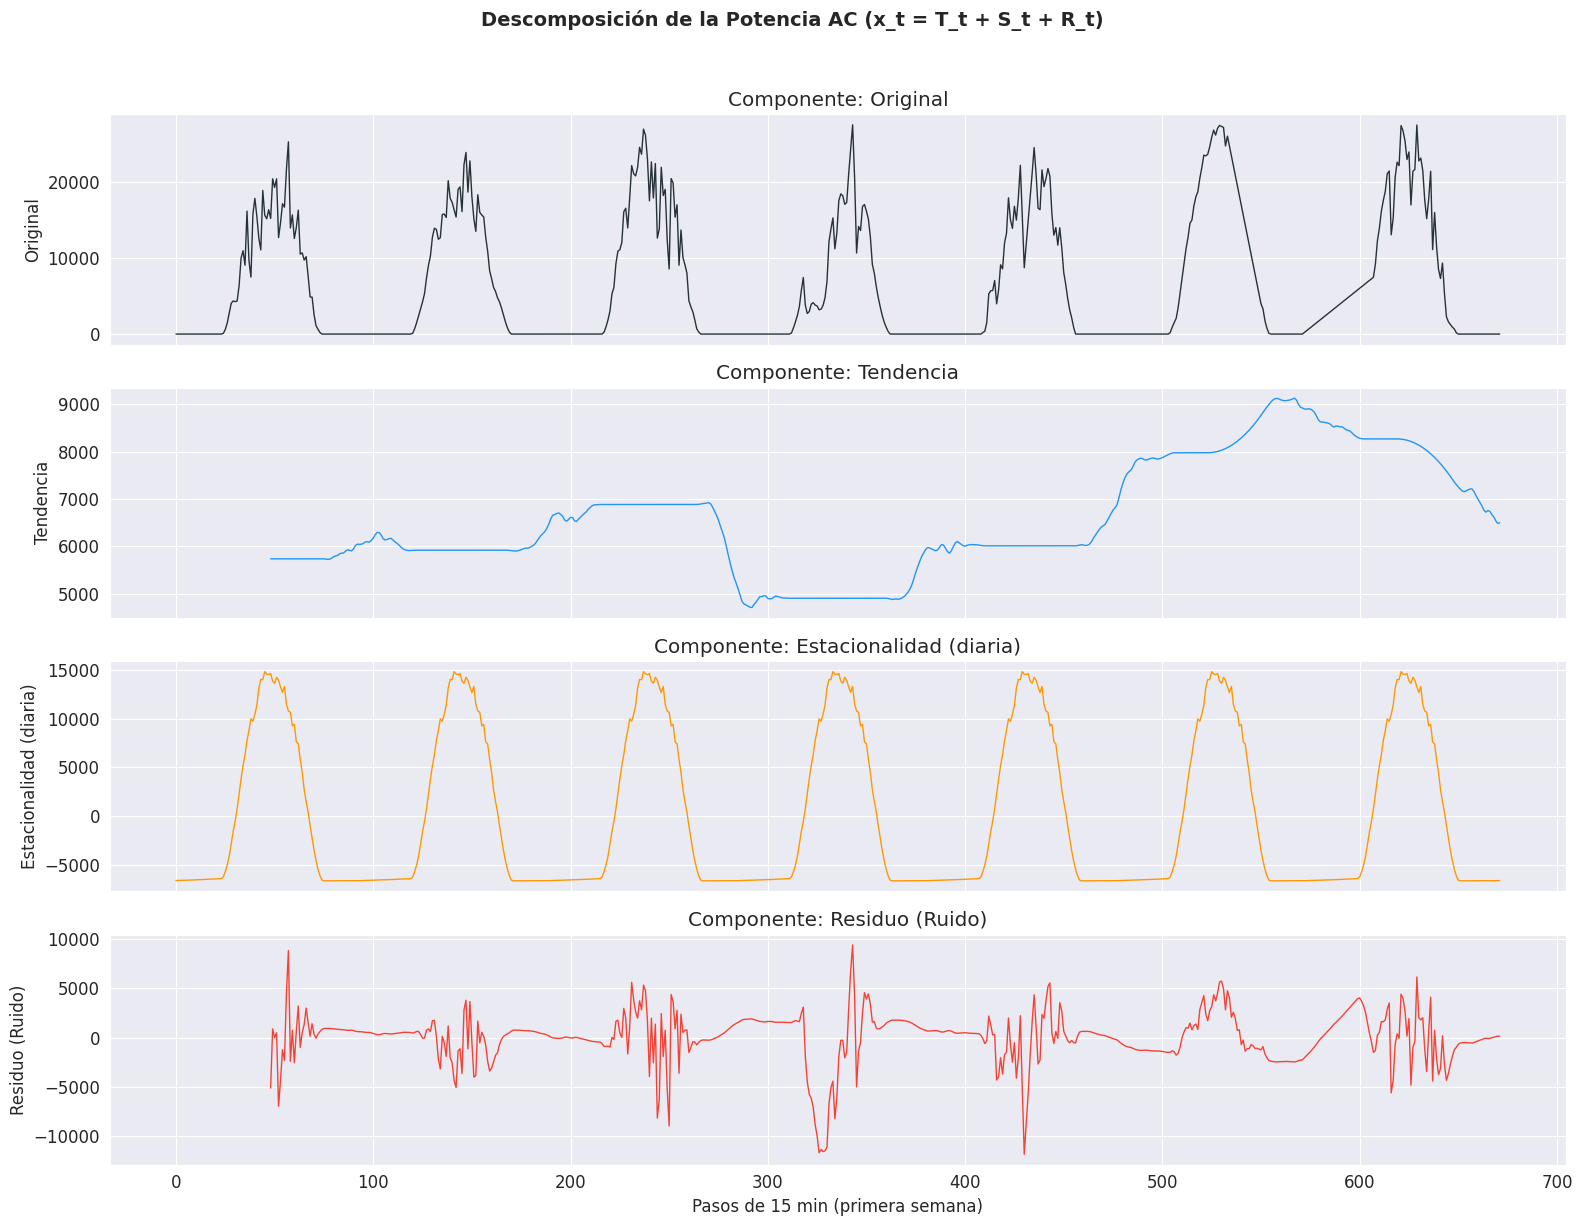

✅ Se observa claramente:
   • Estacionalidad diaria: ciclo día/noche muy marcado (~24h)
   • Tendencia: cambios de un día a otro por nubosidad / clima
   • Residuo: variaciones irregulares (nubes pasajeras)


In [ ]:
# ============================================================
# 📊 Descomposición estacional — Solar
# ============================================================
from statsmodels.tsa.seasonal import seasonal_decompose

solar_values = df_solar['AC_POWER'].values

decomposition = seasonal_decompose(
    solar_values,
    model='additive',
    period=96  # Período diario (96 pasos de 15 min = 24 horas)
)

fig, axes = plt.subplots(4, 1, figsize=(16, 12), sharex=True)
components = [
    ('Original', solar_values, COLORS['actual']),
    ('Tendencia', decomposition.trend, COLORS['lstm']),
    ('Estacionalidad (diaria)', decomposition.seasonal, COLORS['gru']),
    ('Residuo (Ruido)', decomposition.resid, COLORS['rnn'])
]

for ax, (name, data, color) in zip(axes, components):
    ax.plot(data[:672], color=color, linewidth=1)  # Primera semana
    ax.set_ylabel(name)
    ax.set_title(f'Componente: {name}')

axes[-1].set_xlabel('Pasos de 15 min (primera semana)')
fig.suptitle('Descomposición de la Potencia AC (x_t = T_t + S_t + R_t)',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print('✅ Se observa claramente:')
print('   • Estacionalidad diaria: ciclo día/noche muy marcado (~24h)')
print('   • Tendencia: cambios de un día a otro por nubosidad / clima')
print('   • Residuo: variaciones irregulares (nubes pasajeras)')


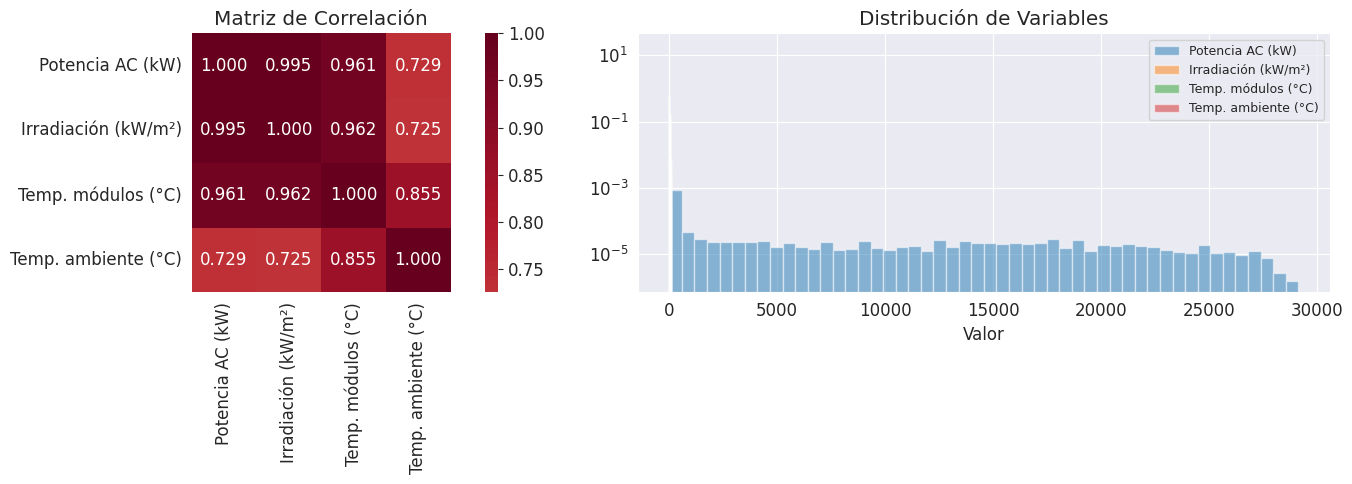

📊 Correlaciones con Potencia AC (kW):
   Irradiación (kW/m²): 0.995
   Temp. módulos (°C): 0.961
   Temp. ambiente (°C): 0.729


In [ ]:
# ============================================================
# 🔗 Análisis de correlación entre variables — Solar
# ============================================================

# Features seleccionadas (la variable a predecir va SIEMPRE en la columna 0)
selected_features_s = ['AC_POWER', 'IRRADIATION', 'MODULE_TEMPERATURE', 'AMBIENT_TEMPERATURE']
feature_names_es_s = ['Potencia AC (kW)', 'Irradiación (kW/m²)', 'Temp. módulos (°C)', 'Temp. ambiente (°C)']

df_multi_s = df_solar[selected_features_s].copy()

# Heatmap de correlación
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

corr_matrix_s = df_multi_s.corr()
sns.heatmap(corr_matrix_s, annot=True, cmap='RdBu_r', center=0,
            xticklabels=feature_names_es_s, yticklabels=feature_names_es_s,
            ax=axes[0], fmt='.3f', square=True)
axes[0].set_title('Matriz de Correlación')

# Distribuciones
for col, name in zip(selected_features_s, feature_names_es_s):
    axes[1].hist(df_multi_s[col].values, bins=50, alpha=0.5, label=name, density=True)
axes[1].set_title('Distribución de Variables')
axes[1].legend(fontsize=9)
axes[1].set_xlabel('Valor')
axes[1].set_yscale('log')

plt.tight_layout()
plt.show()

print(f'📊 Correlaciones con {feature_names_es_s[0]}:')
for feat, name in zip(selected_features_s[1:], feature_names_es_s[1:]):
    print(f'   {name}: {corr_matrix_s.loc["AC_POWER", feat]:.3f}')


### 🔧 Preprocesamiento — Las 3 Reglas de Oro

1. **Regularización temporal**: Los datos están cada 15 min, pero hay instantes faltantes. Se reindexa a una frecuencia fija de 15 min y se **interpola** (~3,100 filas, no hace falta submuestrear).

2. **Split cronológico (NUNCA aleatorio)**: Usamos el primer 80% para entrenamiento y el 20% final para test. Mezclar aleatoriamente crearía **fuga de datos temporal** (data leakage).

3. **Normalización con fit SOLO en train**: El `MinMaxScaler` aprende los rangos solo de los datos de entrenamiento. Si usáramos todo el dataset, el modelo "vería" información futura durante el entrenamiento.

```
INCORRECTO:  scaler.fit_transform(todo_el_dataset)  ← ¡Data leakage!
CORRECTO:    scaler.fit(train); scaler.transform(train); scaler.transform(test)
```

Datos: (3264, 4) (pasos de 15 min, features)

Split cronológico:
  Train: 2,611 pasos
  Test:  653 pasos

Rango de potencia AC en train: [0.00, 29150.21] kW
Pasos del test con el target POR ENCIMA del máximo visto en train: 0.0%


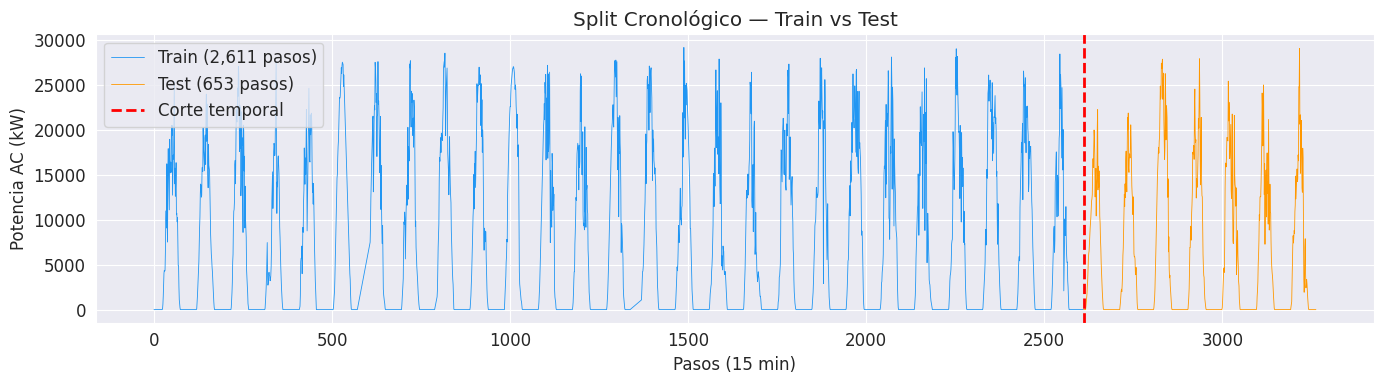

In [ ]:
# ============================================================
# 🔧 Preparación de datos — Solar
# ============================================================

# Extraer features (target = columna 0)
data_s = df_multi_s.values.astype('float32')
print(f'Datos: {data_s.shape} (pasos de 15 min, features)')

# Split cronológico 80/20
split_s = int(len(data_s) * 0.8)
train_s = data_s[:split_s]
test_s = data_s[split_s:]

print(f'\nSplit cronológico:')
print(f'  Train: {len(train_s):,} pasos')
print(f'  Test:  {len(test_s):,} pasos')

# Normalizar CADA feature — fit solo en train
scaler_s = MinMaxScaler()
train_scaled_s = scaler_s.fit_transform(train_s)
test_scaled_s = scaler_s.transform(test_s)

# Guardar rango del target (columna 0) para desnormalizar
min_s = scaler_s.data_min_[0]
max_s = scaler_s.data_max_[0]

def denorm_s(values):
    return values * (max_s - min_s) + min_s

print(f'\nRango de potencia AC en train: [{min_s:.2f}, {max_s:.2f}] kW')
fuera_s = (test_s[:, 0] > train_s[:, 0].max()).mean() * 100
print(f'Pasos del test con el target POR ENCIMA del máximo visto en train: {fuera_s:.1f}%')

# Visualizar split
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(range(len(train_s)), train_s[:, 0], color=COLORS['lstm'],
        label=f'Train ({len(train_s):,} pasos)', linewidth=0.6)
ax.plot(range(len(train_s), len(data_s)), test_s[:, 0], color=COLORS['gru'],
        label=f'Test ({len(test_s):,} pasos)', linewidth=0.6)
ax.axvline(x=split_s, color='red', linestyle='--', linewidth=2, label='Corte temporal')
ax.set_xlabel('Pasos (15 min)')
ax.set_ylabel('Potencia AC (kW)')
ax.set_title('Split Cronológico — Train vs Test')
ax.legend()
plt.tight_layout()
plt.show()


Ventana: 96 pasos (96 pasos de 15 min = 1 día de historia) → Predecir: 1 paso

Shapes multivariados:
  X_train: (2515, 96, 4)  (muestras, 96 pasos, 4 features)
  y_train: (2515,)  (predecir solo potencia AC)
  X_test:  (557, 96, 4)
  y_test:  (557,)

Objetivo del modelo: valor normalizado del siguiente paso


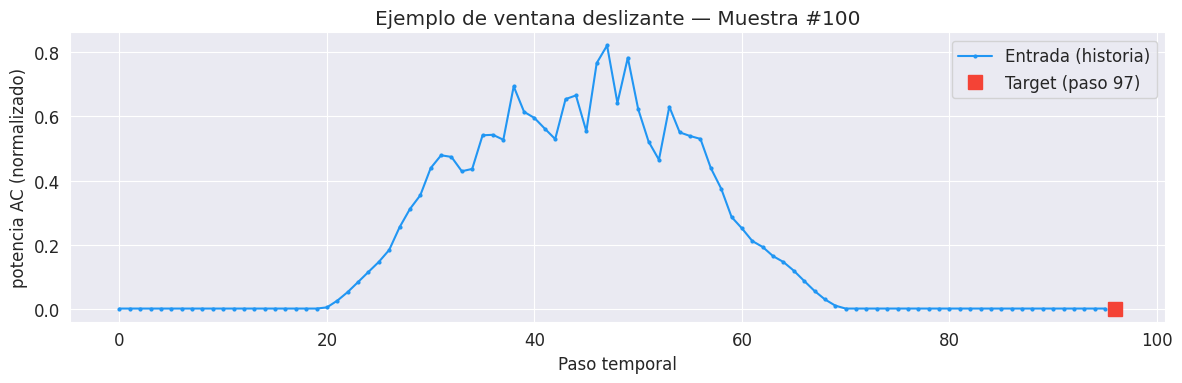

In [ ]:
# ============================================================
# 🪟 Creación de ventanas deslizantes — Solar
# ============================================================
WINDOW_S = 96   # 96 pasos de 15 min = 1 día de historia
HORIZON_S = 1        # Predecir 1 paso adelante (15 min)

X_train_s, y_train_s = create_sequences(train_scaled_s, WINDOW_S, HORIZON_S)
X_test_s, y_test_s = create_sequences(test_scaled_s, WINDOW_S, HORIZON_S)

# Objetivo del modelo: predecir el valor normalizado del siguiente paso (igual que en la Sesión 10-A)
PREDECIR_DELTA_S = False
if PREDECIR_DELTA_S:
    base_train_s = X_train_s[:, -1, 0]   # último valor conocido de cada ventana
    base_test_s = X_test_s[:, -1, 0]
else:
    base_train_s = np.zeros(len(X_train_s))
    base_test_s = np.zeros(len(X_test_s))
y_train_fit_s = y_train_s - base_train_s   # lo que realmente aprende el modelo

print(f'Ventana: {WINDOW_S} pasos (96 pasos de 15 min = 1 día de historia) → Predecir: {HORIZON_S} paso')
print(f'\nShapes multivariados:')
print(f'  X_train: {X_train_s.shape}  (muestras, {WINDOW_S} pasos, {len(selected_features_s)} features)')
print(f'  y_train: {y_train_s.shape}  (predecir solo potencia AC)')
print(f'  X_test:  {X_test_s.shape}')
print(f'  y_test:  {y_test_s.shape}')
print(f'\nObjetivo del modelo: {"variación respecto al último valor" if PREDECIR_DELTA_S else "valor normalizado del siguiente paso"}')

# Visualizar una ventana de ejemplo
fig, ax = plt.subplots(figsize=(12, 4))
sample_idx = 100
window = X_train_s[sample_idx, :, 0]
target = y_train_s[sample_idx]
ax.plot(range(WINDOW_S), window, 'o-', color=COLORS['lstm'],
        markersize=2, label='Entrada (historia)')
ax.plot(WINDOW_S, target, 's', color=COLORS['rnn'],
        markersize=10, label=f'Target (paso {WINDOW_S+1})')
ax.set_xlabel('Paso temporal')
ax.set_ylabel('potencia AC (normalizado)')
ax.set_title(f'Ejemplo de ventana deslizante — Muestra #{sample_idx}')
ax.legend()
plt.tight_layout()
plt.show()


In [ ]:
# ============================================================
# 🏗️ Modelo LSTM Stacked (apilado) — Solar
# ============================================================
tf.random.set_seed(42)

model_lstm_s = models.Sequential([
    layers.LSTM(128, return_sequences=True,
                input_shape=(WINDOW_S, len(selected_features_s)),
                name='lstm_128'),
    layers.Dropout(0.3, name='drop_1'),
    layers.LSTM(64, name='lstm_64'),
    layers.Dropout(0.2, name='drop_2'),
    layers.Dense(32, activation='relu', name='dense_32'),
    layers.Dense(1, name='salida')
], name='LSTM_Stacked_Solar')

model_lstm_s.compile(optimizer='adam', loss='mse', metrics=['mae'])

print('=== LSTM Stacked — Solar ===')
model_lstm_s.summary()
lstm_params_s = model_lstm_s.count_params()
print(f'\nTotal parámetros: {lstm_params_s:,}')


=== LSTM Stacked — Solar ===


Model: "LSTM_Stacked_Solar"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_128 (LSTM)                 │ (None, 96, 128)        │        68,096 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop_1 (Dropout)                │ (None, 96, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_64 (LSTM)                  │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop_2 (Dropout)                │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_32 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida (Dense)                  │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 119,617 (467.25 KB)

 Trainable params: 119,617 (467.25 KB)

 Non-trainable params: 0 (0.00 B)


Total parámetros: 119,617


In [ ]:
# ============================================================
# 🏗️ Modelo GRU Stacked (apilado) — Solar
# ============================================================
tf.random.set_seed(42)

model_gru_s = models.Sequential([
    layers.GRU(128, return_sequences=True,
               input_shape=(WINDOW_S, len(selected_features_s)),
               name='gru_128'),
    layers.Dropout(0.3, name='drop_1'),
    layers.GRU(64, name='gru_64'),
    layers.Dropout(0.2, name='drop_2'),
    layers.Dense(32, activation='relu', name='dense_32'),
    layers.Dense(1, name='salida')
], name='GRU_Stacked_Solar')

model_gru_s.compile(optimizer='adam', loss='mse', metrics=['mae'])

print('=== GRU Stacked — Solar ===')
model_gru_s.summary()
gru_params_s = model_gru_s.count_params()
print(f'\nTotal parámetros: {gru_params_s:,}')
print(f'\n📊 Diferencia: LSTM tiene {lstm_params_s - gru_params_s:,} parámetros más que GRU')
print(f'   GRU es {(1 - gru_params_s/lstm_params_s)*100:.1f}% más ligero')


=== GRU Stacked — Solar ===


Model: "GRU_Stacked_Solar"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru_128 (GRU)                   │ (None, 96, 128)        │        51,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop_1 (Dropout)                │ (None, 96, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_64 (GRU)                    │ (None, 64)             │        37,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop_2 (Dropout)                │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_32 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida (Dense)                  │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 90,817 (354.75 KB)

 Trainable params: 90,817 (354.75 KB)

 Non-trainable params: 0 (0.00 B)


Total parámetros: 90,817

📊 Diferencia: LSTM tiene 28,800 parámetros más que GRU
   GRU es 24.1% más ligero


In [ ]:
# ============================================================
# 🚀 Entrenamiento de ambos modelos — Solar
# ============================================================
EPOCHS = 30
BATCH_SIZE = 64

cb_factory = lambda: [
    callbacks.EarlyStopping(patience=5, restore_best_weights=True, verbose=0),
    callbacks.ReduceLROnPlateau(factor=0.5, patience=3, verbose=0)
]

# Entrenar LSTM
print('🔵 Entrenando LSTM Stacked...')
t0 = time.time()
hist_lstm_s = model_lstm_s.fit(
    X_train_s, y_train_fit_s,
    epochs=EPOCHS, batch_size=BATCH_SIZE,
    validation_split=0.15, callbacks=cb_factory(), verbose=0
)
time_lstm_s = time.time() - t0
print(f'   ⏱️ {time_lstm_s:.1f}s | Épocas: {len(hist_lstm_s.history["loss"])} | Mejor val_loss: {min(hist_lstm_s.history["val_loss"]):.6f}')

# Entrenar GRU
print('🟠 Entrenando GRU Stacked...')
t0 = time.time()
hist_gru_s = model_gru_s.fit(
    X_train_s, y_train_fit_s,
    epochs=EPOCHS, batch_size=BATCH_SIZE,
    validation_split=0.15, callbacks=cb_factory(), verbose=0
)
time_gru_s = time.time() - t0
print(f'   ⏱️ {time_gru_s:.1f}s | Épocas: {len(hist_gru_s.history["loss"])} | Mejor val_loss: {min(hist_gru_s.history["val_loss"]):.6f}')

print(f'\n⚡ GRU fue {time_lstm_s/time_gru_s:.1f}x más rápido que LSTM')


🔵 Entrenando LSTM Stacked...
   ⏱️ 18.7s | Épocas: 24 | Mejor val_loss: 0.006711
🟠 Entrenando GRU Stacked...
   ⏱️ 17.2s | Épocas: 30 | Mejor val_loss: 0.005964

⚡ GRU fue 1.1x más rápido que LSTM


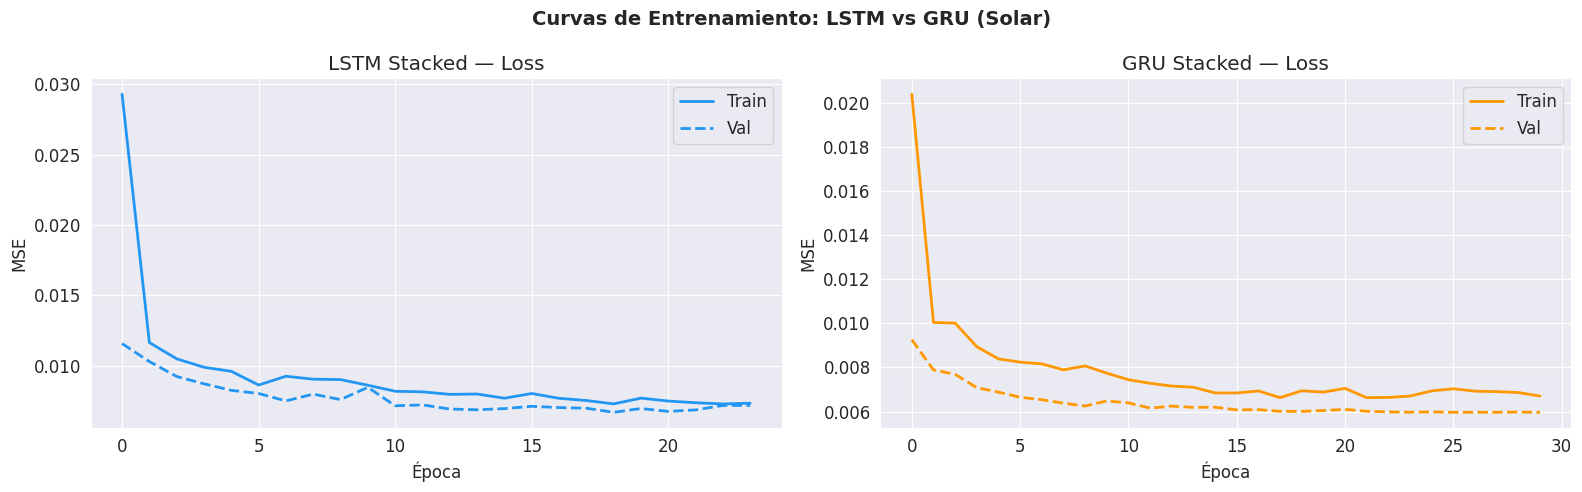

In [ ]:
# ============================================================
# 📉 Curvas de entrenamiento — LSTM vs GRU — Solar
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# LSTM
axes[0].plot(hist_lstm_s.history['loss'], color=COLORS['lstm'],
             label='Train', linewidth=2)
axes[0].plot(hist_lstm_s.history['val_loss'], color=COLORS['lstm'],
             linestyle='--', label='Val', linewidth=2)
axes[0].set_title('LSTM Stacked — Loss')
axes[0].set_xlabel('Época')
axes[0].set_ylabel('MSE')
axes[0].legend()

# GRU
axes[1].plot(hist_gru_s.history['loss'], color=COLORS['gru'],
             label='Train', linewidth=2)
axes[1].plot(hist_gru_s.history['val_loss'], color=COLORS['gru'],
             linestyle='--', label='Val', linewidth=2)
axes[1].set_title('GRU Stacked — Loss')
axes[1].set_xlabel('Época')
axes[1].set_ylabel('MSE')
axes[1].legend()

plt.suptitle('Curvas de Entrenamiento: LSTM vs GRU (Solar)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


In [ ]:
# ============================================================
# 🏗️ Modelos univariados de referencia (LSTM y GRU simples) — Solar
# ============================================================
# Misma arquitectura del Ejemplo 1: una sola capa de 64 unidades + Dropout.
# Usan SOLO la variable objetivo (columna 0) para comparar contra el multivariado.
X_train_u_s = X_train_s[:, :, :1]
X_test_u_s = X_test_s[:, :, :1]

uni_models_s = {}
for kind, Layer in [('LSTM', layers.LSTM), ('GRU', layers.GRU)]:
    tf.random.set_seed(42)
    m_uni = models.Sequential([
        Layer(64, input_shape=(WINDOW_S, 1), name=f'{kind.lower()}_64'),
        layers.Dropout(0.2, name='dropout'),
        layers.Dense(1, name='salida')
    ], name=f'{kind}_Basico_Solar')
    m_uni.compile(optimizer='adam', loss='mse', metrics=['mae'])

    print(f'Entrenando {kind} univariado...')
    t0 = time.time()
    h_uni = m_uni.fit(
        X_train_u_s, y_train_fit_s,
        epochs=EPOCHS, batch_size=BATCH_SIZE,
        validation_split=0.15, callbacks=cb_factory(), verbose=0
    )
    uni_models_s[kind] = {
        'model': m_uni, 'history': h_uni,
        'time': time.time() - t0, 'params': m_uni.count_params()
    }
    print(f'   ⏱️ {uni_models_s[kind]["time"]:.1f}s | Params: {uni_models_s[kind]["params"]:,}')


Entrenando LSTM univariado...
   ⏱️ 12.7s | Params: 16,961
Entrenando GRU univariado...
   ⏱️ 12.2s | Params: 12,929


In [ ]:
# ============================================================
# 📏 Comparación: Naive vs LSTM vs GRU (uni y multivariado) — Solar
# ============================================================

# Predicciones multivariadas
pred_lstm_m_s = model_lstm_s.predict(X_test_s, verbose=0).flatten() + base_test_s
pred_gru_m_s = model_gru_s.predict(X_test_s, verbose=0).flatten() + base_test_s

# Predicciones univariadas
pred_lstm_u_s = uni_models_s['LSTM']['model'].predict(X_test_u_s, verbose=0).flatten() + base_test_s
pred_gru_u_s = uni_models_s['GRU']['model'].predict(X_test_u_s, verbose=0).flatten() + base_test_s

# Baseline naive: predecir el último valor conocido de la ventana
y_naive_s = X_test_s[:, -1, 0]

# Desnormalizar para métricas interpretables
y_test_real_s = denorm_s(y_test_s)
pred_lstm_real_s = denorm_s(pred_lstm_m_s)
pred_gru_real_s = denorm_s(pred_gru_m_s)
pred_lstm_u_real_s = denorm_s(pred_lstm_u_s)
pred_gru_u_real_s = denorm_s(pred_gru_u_s)
y_naive_real_s = denorm_s(y_naive_s)

# Métricas
res_s = {
    'Naive':             {**evaluate_forecast(y_test_real_s, y_naive_real_s),      'params': 0, 'time': 0.0},
    'LSTM Univariado':   {**evaluate_forecast(y_test_real_s, pred_lstm_u_real_s), 'params': uni_models_s['LSTM']['params'], 'time': uni_models_s['LSTM']['time']},
    'GRU Univariado':    {**evaluate_forecast(y_test_real_s, pred_gru_u_real_s),  'params': uni_models_s['GRU']['params'], 'time': uni_models_s['GRU']['time']},
    'LSTM Multivariado': {**evaluate_forecast(y_test_real_s, pred_lstm_real_s),   'params': lstm_params_s, 'time': time_lstm_s},
    'GRU Multivariado':  {**evaluate_forecast(y_test_real_s, pred_gru_real_s),    'params': gru_params_s, 'time': time_gru_s},
}

print('=' * 88)
print('COMPARACIÓN Solar: Naive vs LSTM vs GRU')
print('=' * 88)
print(f'{"":<20} {"MAE (kW)":<14} {"RMSE (kW)":<14} {"MAPE (%)":<12} {"Params":<10} {"Tiempo (s)":<10}')
print('-' * 88)
for name, r in res_s.items():
    print(f'{name:<20} {r["MAE"]:<14.4f} {r["RMSE"]:<14.4f} {r["MAPE"]:<12.2f} {r["params"]:<10,} {r["time"]:<10.1f}')
print('-' * 88)

naive_mae_s = res_s['Naive']['MAE']
print('\nMejora del MAE respecto al baseline naive:')
for name, r in res_s.items():
    if name != 'Naive':
        print(f'   {name:<20} {(1 - r["MAE"] / naive_mae_s) * 100:+.1f}%')
print('\n⚠️ Nota: el MAPE no es confiable en solar (de noche la potencia es ~0 y el cociente se dispara). Usa MAE y RMSE.')


COMPARACIÓN Solar: Naive vs LSTM vs GRU
                     MAE (kW)       RMSE (kW)      MAPE (%)     Params     Tiempo (s)
----------------------------------------------------------------------------------------
Naive                1178.6384      2228.3897      38.07        0          0.0       
LSTM Univariado      1278.4767      2197.2128      181.07       16,961     12.7      
GRU Univariado       1276.3842      2133.8098      73.64        12,929     12.2      
LSTM Multivariado    1382.5162      2336.0925      198.02       119,617    18.7      
GRU Multivariado     1146.3654      2133.7734      41.01        90,817     17.2      
----------------------------------------------------------------------------------------

Mejora del MAE respecto al baseline naive:
   LSTM Univariado      -8.5%
   GRU Univariado       -8.3%
   LSTM Multivariado    -17.3%
   GRU Multivariado     +2.7%

⚠️ Nota: el MAPE no es confiable en solar (de noche la potencia es ~0 y el cociente se dispara). Usa

Experimentando con diferentes tamaños de ventana (GRU)...
  Ventana= 48 pasos (12h) | MAE: 1237.7670 kW | Tiempo: 8.8s | Params: 13,505
  Ventana= 96 pasos (24h) | MAE: 1321.4374 kW | Tiempo: 8.8s | Params: 13,505
  Ventana=192 pasos (48h) | MAE: 1354.9662 kW | Tiempo: 9.0s | Params: 13,505


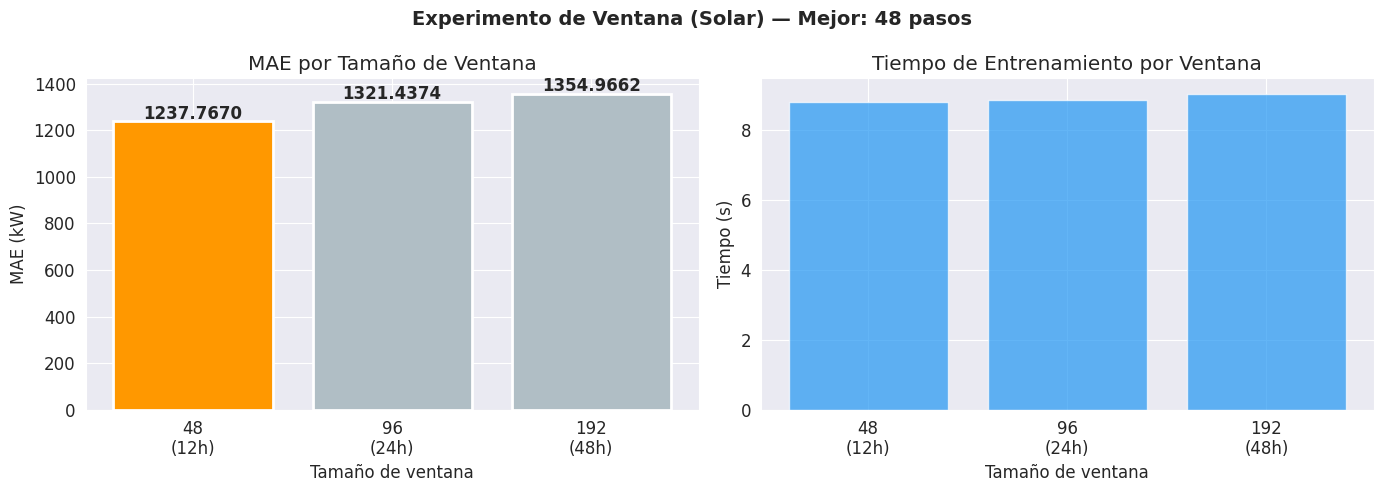

In [ ]:
# ============================================================
# 🔍 Experimento: Tamaño de ventana óptimo — Solar
# ============================================================
windows = [48, 96, 192]  # 12 horas, 1 día, 2 días
window_results_s = {}

print('Experimentando con diferentes tamaños de ventana (GRU)...')
for w in windows:
    tf.random.set_seed(42)

    X_tr, y_tr = create_sequences(train_scaled_s, w, 1)
    X_te, y_te = create_sequences(test_scaled_s, w, 1)
    base_tr = X_tr[:, -1, 0] if PREDECIR_DELTA_S else 0
    base_te = X_te[:, -1, 0] if PREDECIR_DELTA_S else 0

    m = models.Sequential([
        layers.GRU(64, input_shape=(w, len(selected_features_s))),
        layers.Dropout(0.2),
        layers.Dense(1)
    ])
    m.compile(optimizer='adam', loss='mse', metrics=['mae'])

    t0 = time.time()
    m.fit(X_tr, y_tr - base_tr, epochs=20, batch_size=64,
          validation_split=0.15, verbose=0,
          callbacks=[callbacks.EarlyStopping(patience=3,
                     restore_best_weights=True, verbose=0)])
    elapsed = time.time() - t0

    pred = m.predict(X_te, verbose=0).flatten() + base_te
    pred_real = denorm_s(pred)
    y_real = denorm_s(y_te)

    mae = mean_absolute_error(y_real, pred_real)
    window_results_s[w] = {'MAE': mae, 'time': elapsed, 'params': m.count_params()}
    print(f'  Ventana={w:>3} pasos ({f'{w*15/60:.0f}h'}) | MAE: {mae:.4f} kW | Tiempo: {elapsed:.1f}s | Params: {m.count_params():,}')

# Gráfico de comparación
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

w_labels = [f'{w}\n(' + f'{w*15/60:.0f}h' + ')' for w in windows]
maes = [window_results_s[w]['MAE'] for w in windows]
times = [window_results_s[w]['time'] for w in windows]

colors_bar = [COLORS['gru'] if m == min(maes) else '#B0BEC5' for m in maes]
axes[0].bar(w_labels, maes, color=colors_bar, edgecolor='white', linewidth=2)
axes[0].set_ylabel('MAE (kW)')
axes[0].set_xlabel('Tamaño de ventana')
axes[0].set_title('MAE por Tamaño de Ventana')
for i, v in enumerate(maes):
    axes[0].text(i, v * 1.01, f'{v:.4f}', ha='center', fontweight='bold')

axes[1].bar(w_labels, times, color=COLORS['lstm'], alpha=0.7, edgecolor='white')
axes[1].set_ylabel('Tiempo (s)')
axes[1].set_xlabel('Tamaño de ventana')
axes[1].set_title('Tiempo de Entrenamiento por Ventana')

best_w_s = min(window_results_s, key=lambda k: window_results_s[k]['MAE'])
plt.suptitle(f'Experimento de Ventana (Solar) — Mejor: {best_w_s} pasos',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


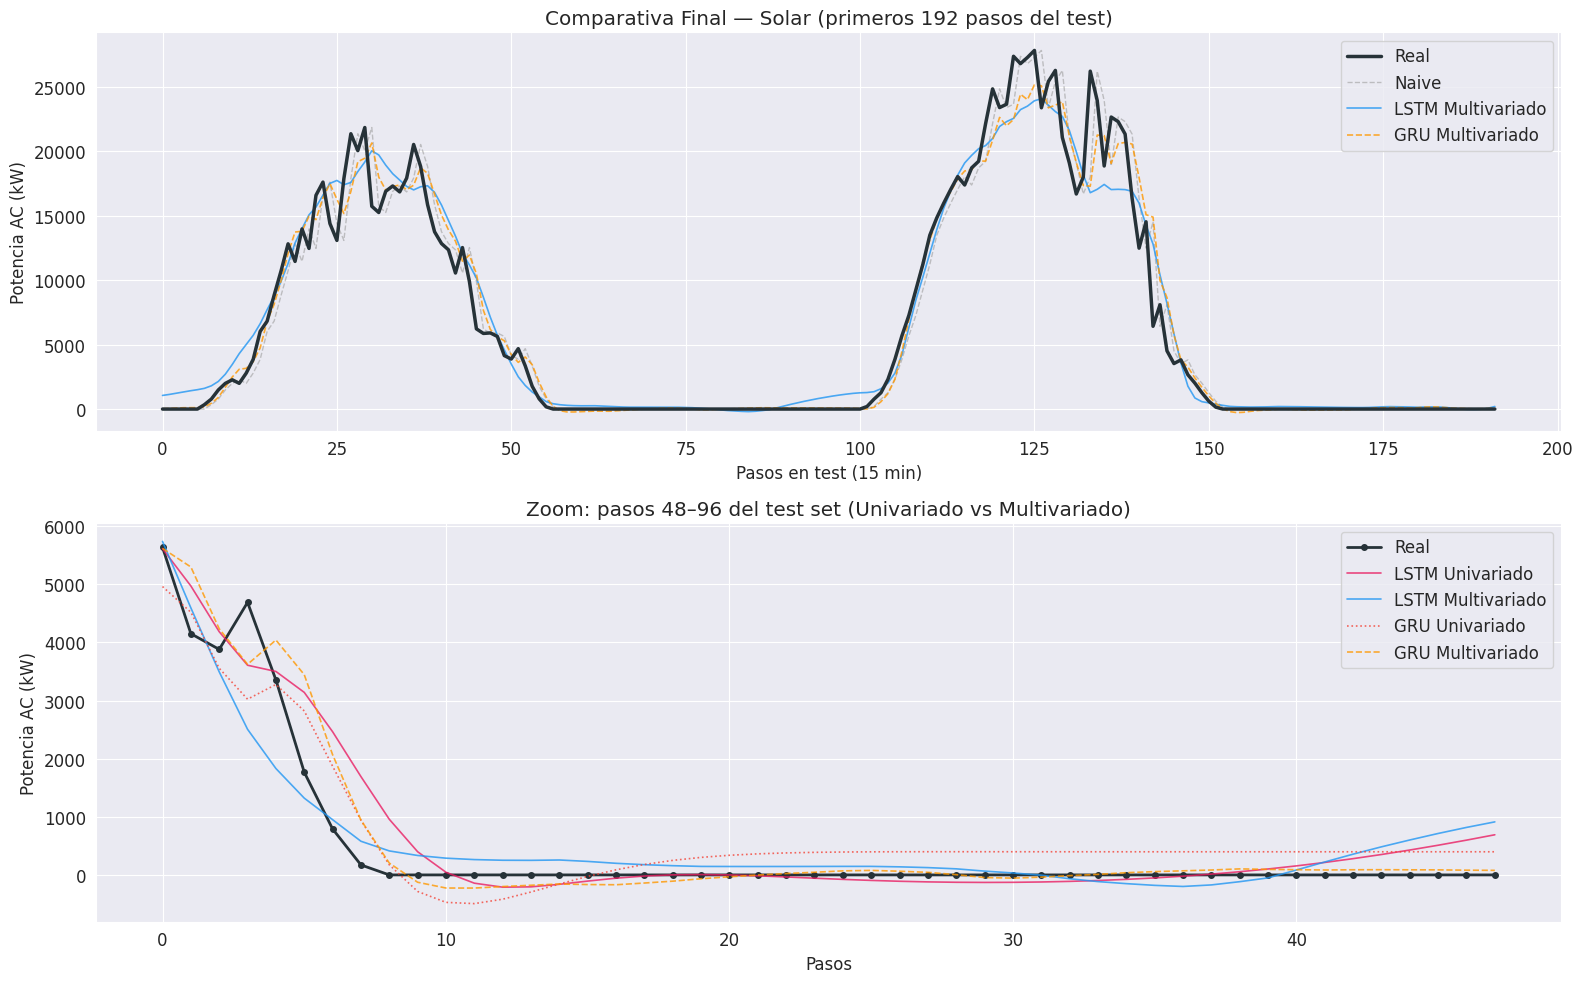

In [ ]:
# ============================================================
# 📊 Visualización final comparativa — Solar
# ============================================================
fig, axes = plt.subplots(2, 1, figsize=(16, 10))

# Subplot 1: primeros pasos del test
n_show = 192
axes[0].plot(y_test_real_s[:n_show], color=COLORS['actual'],
             linewidth=2.5, label='Real', zorder=5)
axes[0].plot(y_naive_real_s[:n_show], color=COLORS['naive'],
             linewidth=1, linestyle='--', alpha=0.6, label='Naive')
axes[0].plot(pred_lstm_real_s[:n_show], color=COLORS['lstm'],
             linewidth=1.2, alpha=0.8, label='LSTM Multivariado')
axes[0].plot(pred_gru_real_s[:n_show], color=COLORS['gru'],
             linewidth=1.2, alpha=0.8, label='GRU Multivariado', linestyle='--')
axes[0].set_xlabel('Pasos en test (15 min)')
axes[0].set_ylabel('Potencia AC (kW)')
axes[0].set_title(f'Comparativa Final — Solar (primeros {n_show} pasos del test)')
axes[0].legend(loc='upper right')

# Subplot 2: Univariado vs Multivariado (zoom)
n_zoom = 48
start = 48
rng = range(n_zoom)
axes[1].plot(rng, y_test_real_s[start:start+n_zoom], 'o-', color=COLORS['actual'],
             linewidth=2, markersize=4, label='Real')
axes[1].plot(rng, pred_lstm_u_real_s[start:start+n_zoom], color=COLORS['pred'],
             linewidth=1.2, alpha=0.8, label='LSTM Univariado')
axes[1].plot(rng, pred_lstm_real_s[start:start+n_zoom], color=COLORS['lstm'],
             linewidth=1.2, alpha=0.8, label='LSTM Multivariado')
axes[1].plot(rng, pred_gru_u_real_s[start:start+n_zoom], color=COLORS['rnn'],
             linewidth=1.2, alpha=0.8, label='GRU Univariado', linestyle=':')
axes[1].plot(rng, pred_gru_real_s[start:start+n_zoom], color=COLORS['gru'],
             linewidth=1.2, alpha=0.8, label='GRU Multivariado', linestyle='--')
axes[1].set_xlabel('Pasos')
axes[1].set_ylabel('Potencia AC (kW)')
axes[1].set_title(f'Zoom: pasos {start}–{start+n_zoom} del test set (Univariado vs Multivariado)')
axes[1].legend(loc='upper right')

plt.tight_layout()
plt.show()


In [ ]:
# ============================================================
# 🧾 Resumen automático de resultados — Solar
# ============================================================
modelos_rnn_s = ['LSTM Univariado', 'GRU Univariado', 'LSTM Multivariado', 'GRU Multivariado']
mejor_s = min(modelos_rnn_s, key=lambda k: res_s[k]['MAE'])
mejora_s = (1 - res_s[mejor_s]['MAE'] / res_s['Naive']['MAE']) * 100

print(f'🏆 Mejor modelo en Solar (menor MAE): {mejor_s}')
print(f'   MAE = {res_s[mejor_s]["MAE"]:.4f} kW ({mejora_s:+.1f}% vs naive)')

lstm_mae = res_s['LSTM Multivariado']['MAE']
gru_mae = res_s['GRU Multivariado']['MAE']
ganador = 'GRU' if gru_mae < lstm_mae else 'LSTM'
print(f'\n⚖️ Multivariado: {ganador} gana por {abs(lstm_mae - gru_mae):.4f} kW de MAE')
print(f'⚡ GRU entrenó {time_lstm_s/time_gru_s:.1f}x más rápido y usa {(1 - gru_params_s/lstm_params_s)*100:.1f}% menos parámetros')

for kind in ['LSTM', 'GRU']:
    uni, multi = res_s[f'{kind} Univariado']['MAE'], res_s[f'{kind} Multivariado']['MAE']
    print(f'📐 {kind}: multivariado {"mejora" if multi < uni else "NO mejora"} al univariado ({uni:.4f} → {multi:.4f} kW)')

if mejora_s <= 0:
    print('\n⚠️ Ningún modelo supera al baseline naive en este dataset.')


🏆 Mejor modelo en Solar (menor MAE): GRU Multivariado
   MAE = 1146.3654 kW (+2.7% vs naive)

⚖️ Multivariado: GRU gana por 236.1508 kW de MAE
⚡ GRU entrenó 1.1x más rápido y usa 24.1% menos parámetros
📐 LSTM: multivariado NO mejora al univariado (1278.4767 → 1382.5162 kW)
📐 GRU: multivariado mejora al univariado (1276.3842 → 1146.3654 kW)


### 💡 Conclusiones — Solar

> _Completa esta sección con los resultados que obtuviste al ejecutar el notebook (puedes apoyarte en la celda de resumen automático)._

1. **¿Qué modelo rindió mejor, LSTM o GRU?** _(MAE, RMSE y diferencia entre ambos)_
2. **¿Superaron al baseline naive?** _(porcentaje de mejora del MAE; si no lo superaron, explica por qué)_
3. **Univariado vs multivariado:** _(¿mejoró al agregar irradiación y temperaturas? Se espera que la irradiación esté muy correlacionada con la potencia.)_
4. **Tamaño de ventana:** _(¿cuál fue la mejor ventana? ¿ventanas más largas ayudaron o solo costaron más tiempo?)_
5. **Eficiencia:** _(parámetros y tiempo de entrenamiento de GRU frente a LSTM)_

> ⚡ **Pregunta para reflexionar:** ¿Qué pasaría si quisiéramos predecir **varias horas adelante** (horizon mayor) en lugar de 15 minutos?

---

## 🔶 Dataset 2: Precio del Cobre — LSTM vs GRU

**Objetivo:** Comparar LSTM y GRU para pronosticar el **precio de cierre del cobre** un día adelante, usando también apertura, máximo, mínimo y volumen como entrada.

**Dataset:** Futuros de cobre COMEX (`HG=F`), precio en USD por libra, frecuencia diaria (solo días hábiles), descargado con `yfinance` desde 2010 y guardado en `/content/data/cobre_HGF.csv`.

**Tarea:** Forecasting multivariado (many-to-one)

**Ajuste respecto al Dataset 1:** en el cobre el modelo predice la *variación* del precio (no el nivel), porque el precio sale del rango visto en entrenamiento (ver Regla 4 del preprocesamiento).

**Contraste con el Dataset 1:** el precio de un commodity es una serie **ruidosa y sin ciclo claro**, a diferencia de la potencia solar, que es casi periódica. Se espera que el baseline naive sea muy difícil de superar.

**Pasos:**
1. Exploración y descomposición de la serie
2. Análisis de correlación entre variables
3. Preprocesamiento: split cronológico, normalización
4. Creación de ventanas deslizantes
5. Modelos LSTM y GRU (apilados) + referencias univariadas
6. Evaluación contra baseline naive
7. Experimento de tamaño de ventana

In [ ]:
# ============================================================
# 📥 Dataset: Cobre (COMEX, HG=F) — se guarda en /content/data
# ============================================================
import os
import shutil
import yfinance as yf
from google.colab import files

# Carpeta de datos en Colab: /content/data
DATA_DIR = '/content/data'
os.makedirs(DATA_DIR, exist_ok=True)
csv_cobre = os.path.join(DATA_DIR, 'cobre_HGF.csv')

if os.path.exists(csv_cobre):
    print(f'✅ Archivo encontrado: {csv_cobre}')
else:
    print('📥 Descargando HG=F con yfinance...')
    descarga = yf.download('HG=F', start='2010-01-01', end='2026-11-19',
                           progress=False, auto_adjust=True)
    if isinstance(descarga.columns, pd.MultiIndex):      # versiones nuevas de yfinance
        descarga.columns = descarga.columns.get_level_values(0)

    if descarga.empty:
        print('⚠️ yfinance no devolvió datos. Sube un CSV histórico de HG=F (Yahoo Finance)')
        print('   con columnas: Date, Open, High, Low, Close, Volume')
        nombre = list(files.upload().keys())[0]
        shutil.move(nombre, csv_cobre)
    else:
        descarga.to_csv(csv_cobre)
        print(f'💾 Guardado en {csv_cobre}')

raw = pd.read_csv(csv_cobre, parse_dates=['Date'], index_col='Date')

df_cobre = raw[['Close', 'Open', 'High', 'Low', 'Volume']].dropna().copy()

print(f'Shape del dataset: {df_cobre.shape}')
print(f'Rango temporal: {df_cobre.index[0].date()} → {df_cobre.index[-1].date()}')
print(f'Frecuencia: diaria (días hábiles)')
print(f'\nColumnas disponibles ({len(df_cobre.columns)}):')
for col in df_cobre.columns:
    print(f'  • {col}')

df_cobre.head()


📥 Descargando HG=F con yfinance...
💾 Guardado en /content/data/cobre_HGF.csv
Shape del dataset: (4246, 5)
Rango temporal: 2010-01-04 → 2026-11-18
Frecuencia: diaria (días hábiles)

Columnas disponibles (5):
  • Close
  • Open
  • High
  • Low
  • Volume


,Close,Open,High,Low,Volume
Date,,,,,
2010-01-04,3.3880,3.3880,3.4090,3.3530,404
2010-01-05,3.3960,3.3960,3.4110,3.3685,242
2010-01-06,3.4775,3.4775,3.4995,3.4335,109
2010-01-07,3.4115,3.4995,3.5235,3.4110,326
2010-01-08,3.3880,3.3880,3.4220,3.3800,311


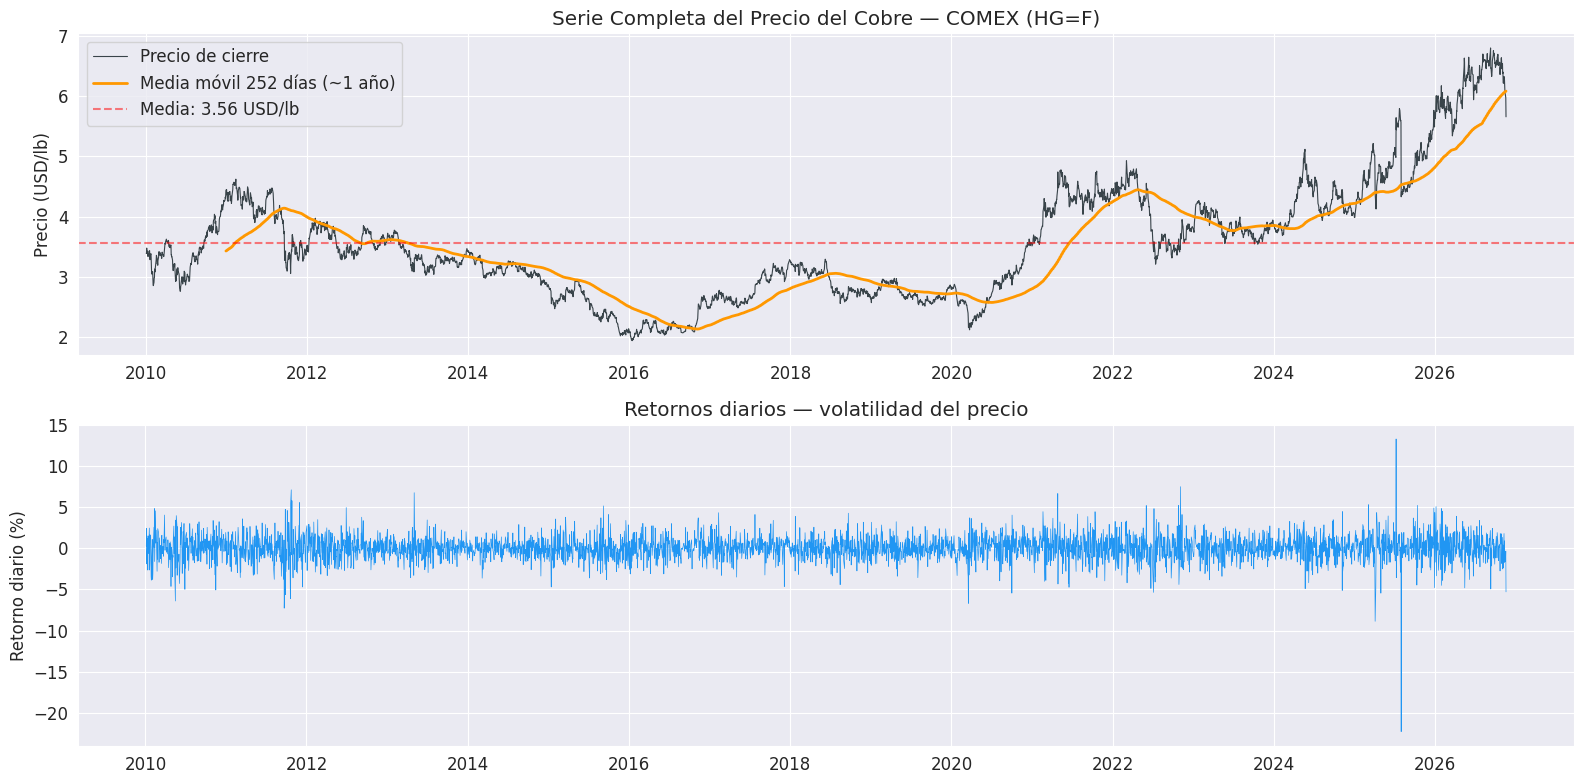

Estadísticas del precio de cierre:
  Mínimo: 1.94 | Máximo: 6.80 | Media: 3.56 USD/lb
  Volatilidad diaria (desv. est. de retornos): 1.52%


In [ ]:
# ============================================================
# 📈 Visualización de la serie completa del precio del cobre
# ============================================================
fig, axes = plt.subplots(2, 1, figsize=(16, 8))

close = df_cobre['Close']

axes[0].plot(close.index, close.values, linewidth=0.8, color=COLORS['actual'], alpha=0.9,
             label='Precio de cierre')
axes[0].plot(close.index, close.rolling(252).mean(), linewidth=2, color=COLORS['gru'],
             label='Media móvil 252 días (~1 año)')
axes[0].axhline(y=close.mean(), color='red', linestyle='--', alpha=0.5,
                label=f'Media: {close.mean():.2f} USD/lb')
axes[0].set_ylabel('Precio (USD/lb)')
axes[0].set_title('Serie Completa del Precio del Cobre — COMEX (HG=F)')
axes[0].legend()

# Retornos diarios: muestran la volatilidad
retornos = close.pct_change().dropna() * 100
axes[1].plot(retornos.index, retornos.values, linewidth=0.5, color=COLORS['lstm'])
axes[1].set_ylabel('Retorno diario (%)')
axes[1].set_title('Retornos diarios — volatilidad del precio')

plt.tight_layout()
plt.show()

print(f'Estadísticas del precio de cierre:')
print(f'  Mínimo: {close.min():.2f} | Máximo: {close.max():.2f} | Media: {close.mean():.2f} USD/lb')
print(f'  Volatilidad diaria (desv. est. de retornos): {retornos.std():.2f}%')


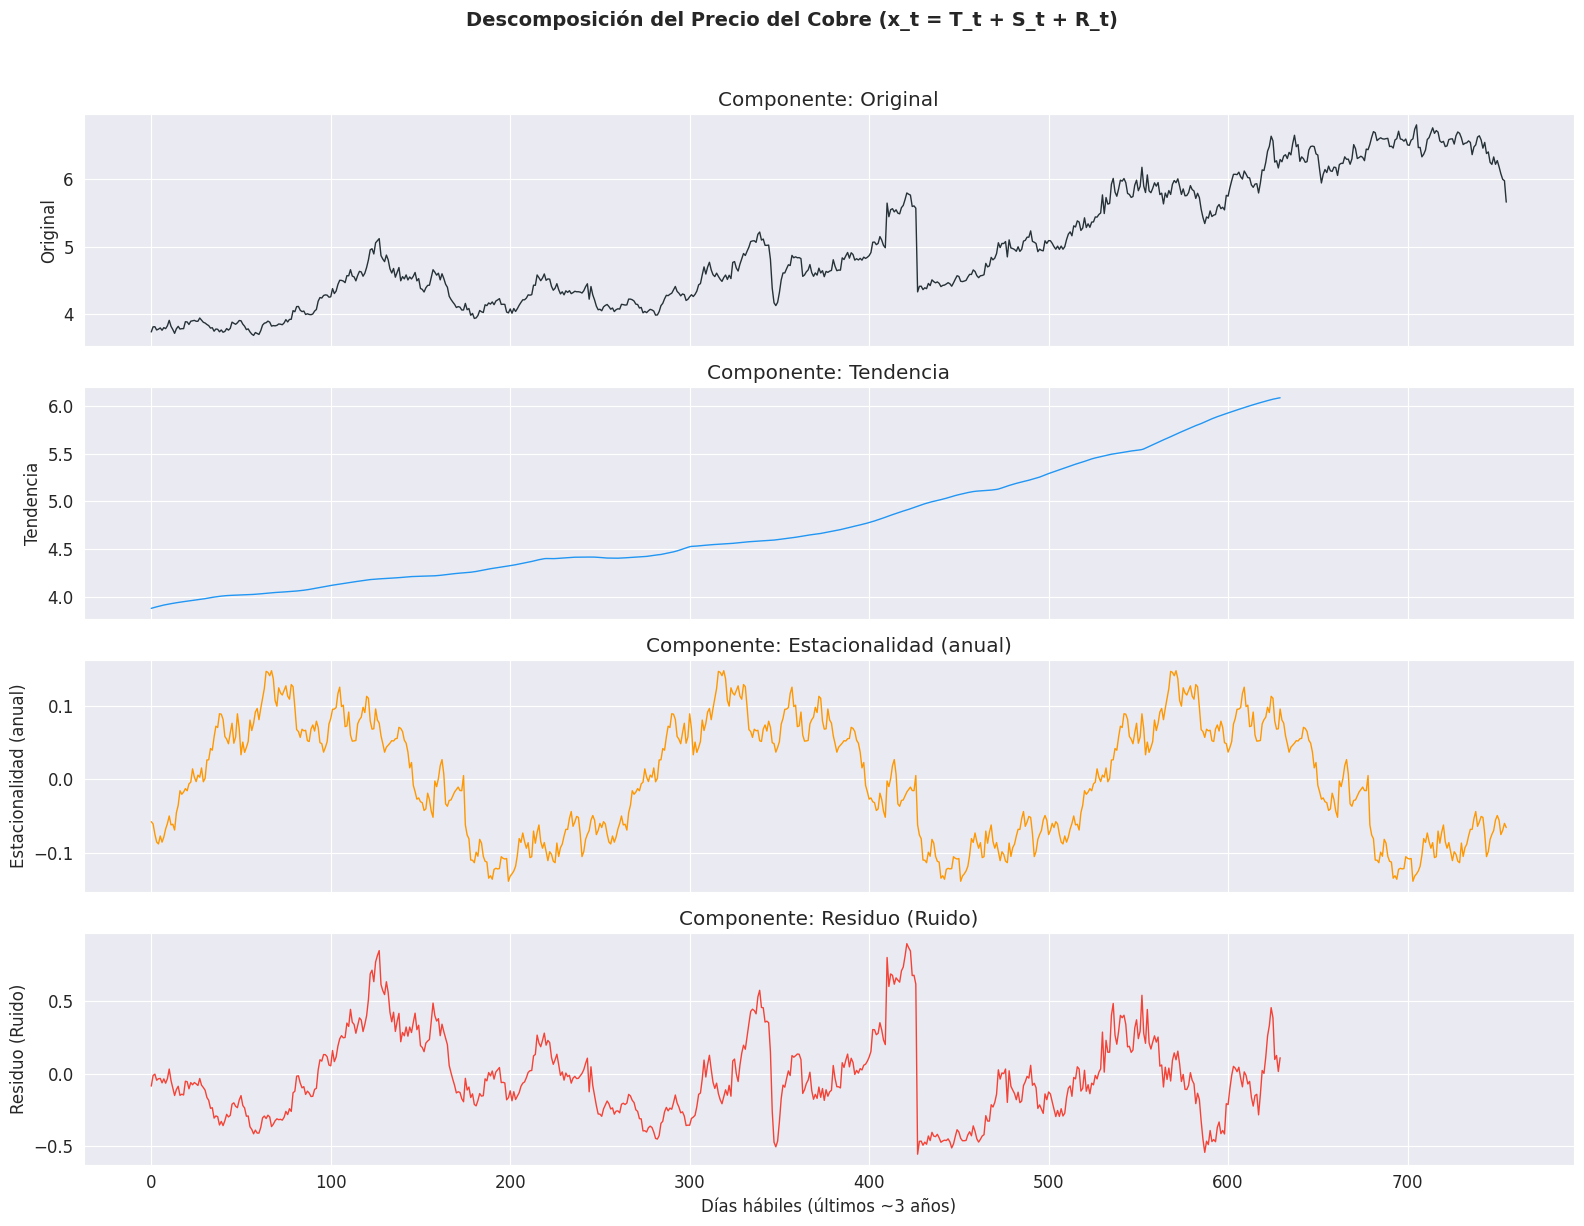

✅ Se observa:
   • Tendencia: dominante (ciclos de precio de varios meses/años)
   • Estacionalidad anual: muy débil comparada con la tendencia
   • Residuo: ruido relevante — el precio es difícil de predecir


In [ ]:
# ============================================================
# 📊 Descomposición estacional — Cobre
# ============================================================
from statsmodels.tsa.seasonal import seasonal_decompose

cobre_values = df_cobre['Close'].values

decomposition_c = seasonal_decompose(
    cobre_values,
    model='additive',
    period=252  # ~1 año de días hábiles
)

fig, axes = plt.subplots(4, 1, figsize=(16, 12), sharex=True)
components = [
    ('Original', cobre_values, COLORS['actual']),
    ('Tendencia', decomposition_c.trend, COLORS['lstm']),
    ('Estacionalidad (anual)', decomposition_c.seasonal, COLORS['gru']),
    ('Residuo (Ruido)', decomposition_c.resid, COLORS['rnn'])
]

for ax, (name, data, color) in zip(axes, components):
    ax.plot(data[-756:], color=color, linewidth=1)  # Últimos ~3 años
    ax.set_ylabel(name)
    ax.set_title(f'Componente: {name}')

axes[-1].set_xlabel('Días hábiles (últimos ~3 años)')
fig.suptitle('Descomposición del Precio del Cobre (x_t = T_t + S_t + R_t)',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print('✅ Se observa:')
print('   • Tendencia: dominante (ciclos de precio de varios meses/años)')
print('   • Estacionalidad anual: muy débil comparada con la tendencia')
print('   • Residuo: ruido relevante — el precio es difícil de predecir')


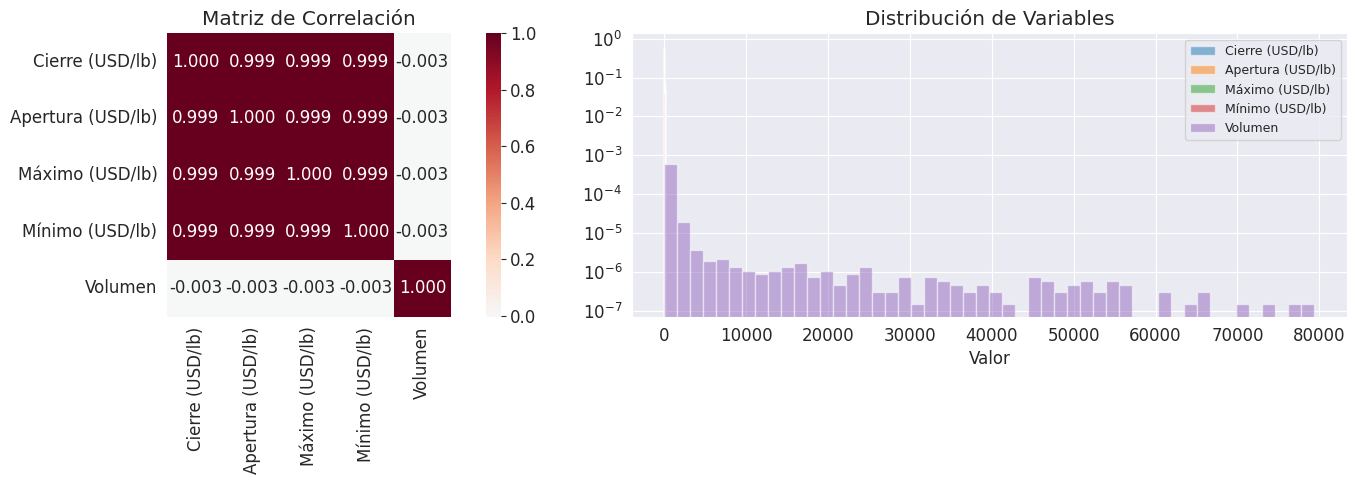

📊 Correlaciones con Cierre (USD/lb):
   Apertura (USD/lb): 0.999
   Máximo (USD/lb): 0.999
   Mínimo (USD/lb): 0.999
   Volumen: -0.003


In [ ]:
# ============================================================
# 🔗 Análisis de correlación entre variables — Cobre
# ============================================================

# Features seleccionadas (la variable a predecir va SIEMPRE en la columna 0)
selected_features_c = ['Close', 'Open', 'High', 'Low', 'Volume']
feature_names_es_c = ['Cierre (USD/lb)', 'Apertura (USD/lb)', 'Máximo (USD/lb)', 'Mínimo (USD/lb)', 'Volumen']

df_multi_c = df_cobre[selected_features_c].copy()

# Heatmap de correlación
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

corr_matrix_c = df_multi_c.corr()
sns.heatmap(corr_matrix_c, annot=True, cmap='RdBu_r', center=0,
            xticklabels=feature_names_es_c, yticklabels=feature_names_es_c,
            ax=axes[0], fmt='.3f', square=True)
axes[0].set_title('Matriz de Correlación')

# Distribuciones
for col, name in zip(selected_features_c, feature_names_es_c):
    axes[1].hist(df_multi_c[col].values, bins=50, alpha=0.5, label=name, density=True)
axes[1].set_title('Distribución de Variables')
axes[1].legend(fontsize=9)
axes[1].set_xlabel('Valor')
axes[1].set_yscale('log')

plt.tight_layout()
plt.show()

print(f'📊 Correlaciones con {feature_names_es_c[0]}:')
for feat, name in zip(selected_features_c[1:], feature_names_es_c[1:]):
    print(f'   {name}: {corr_matrix_c.loc["Close", feat]:.3f}')


### 🔧 Preprocesamiento — Las 3 Reglas de Oro

1. **Sin submuestreo**: Los datos ya son diarios (~4,200 filas), un tamaño manejable. Solo se eliminan filas con valores faltantes (`dropna`).

2. **Split cronológico (NUNCA aleatorio)**: Usamos el primer 80% para entrenamiento y el 20% final para test. Mezclar aleatoriamente crearía **fuga de datos temporal** (data leakage).

3. **Normalización con fit SOLO en train**: El `MinMaxScaler` aprende los rangos solo de los datos de entrenamiento. En el cobre esto tiene una consecuencia importante: el precio del test sube por encima del máximo visto en train, así que los valores normalizados pasan de 1.

4. **Objetivo = variación, no nivel (solo cobre)**: un modelo que predice el *nivel* del precio no sabe extrapolar fuera del rango de entrenamiento y termina muy por debajo del naive. Por eso el modelo aprende la **variación respecto al último valor** de la ventana y luego se le suma ese valor (`pred = último valor + variación predicha`). Así parte del naive y solo aprende la corrección. Las métricas se calculan sobre el precio real, igual que en solar.

```
INCORRECTO:  scaler.fit_transform(todo_el_dataset)  ← ¡Data leakage!
CORRECTO:    scaler.fit(train); scaler.transform(train); scaler.transform(test)
```

Datos: (4246, 5) (pasos de 1 día hábil, features)

Split cronológico:
  Train: 3,396 pasos
  Test:  850 pasos

Rango de precio de cierre en train: [1.94, 4.93] USD/lb
Pasos del test con el target POR ENCIMA del máximo visto en train: 38.2%


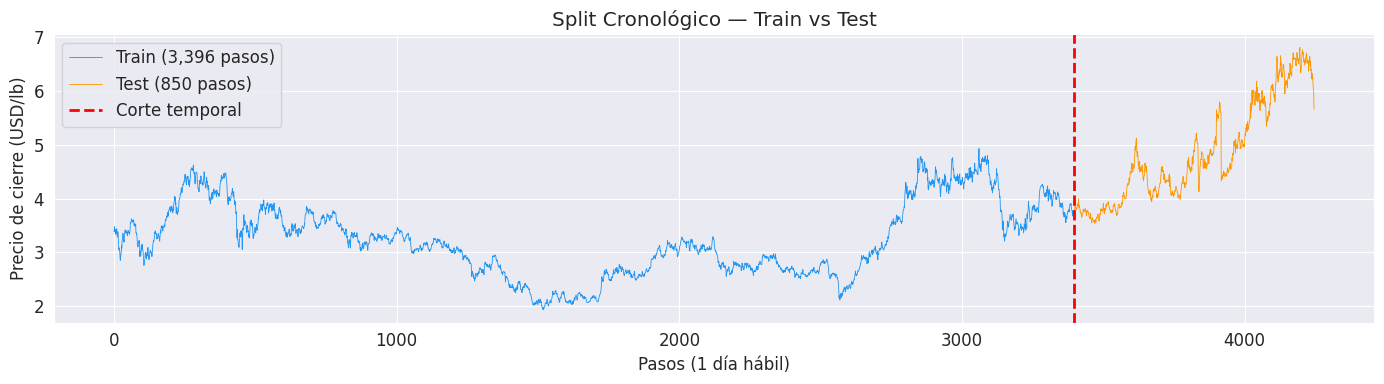

In [ ]:
# ============================================================
# 🔧 Preparación de datos — Cobre
# ============================================================

# Extraer features (target = columna 0)
data_c = df_multi_c.values.astype('float32')
print(f'Datos: {data_c.shape} (pasos de 1 día hábil, features)')

# Split cronológico 80/20
split_c = int(len(data_c) * 0.8)
train_c = data_c[:split_c]
test_c = data_c[split_c:]

print(f'\nSplit cronológico:')
print(f'  Train: {len(train_c):,} pasos')
print(f'  Test:  {len(test_c):,} pasos')

# Normalizar CADA feature — fit solo en train
scaler_c = MinMaxScaler()
train_scaled_c = scaler_c.fit_transform(train_c)
test_scaled_c = scaler_c.transform(test_c)

# Guardar rango del target (columna 0) para desnormalizar
min_c = scaler_c.data_min_[0]
max_c = scaler_c.data_max_[0]

def denorm_c(values):
    return values * (max_c - min_c) + min_c

print(f'\nRango de precio de cierre en train: [{min_c:.2f}, {max_c:.2f}] USD/lb')
fuera_c = (test_c[:, 0] > train_c[:, 0].max()).mean() * 100
print(f'Pasos del test con el target POR ENCIMA del máximo visto en train: {fuera_c:.1f}%')

# Visualizar split
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(range(len(train_c)), train_c[:, 0], color=COLORS['lstm'],
        label=f'Train ({len(train_c):,} pasos)', linewidth=0.6)
ax.plot(range(len(train_c), len(data_c)), test_c[:, 0], color=COLORS['gru'],
        label=f'Test ({len(test_c):,} pasos)', linewidth=0.6)
ax.axvline(x=split_c, color='red', linestyle='--', linewidth=2, label='Corte temporal')
ax.set_xlabel('Pasos (1 día hábil)')
ax.set_ylabel('Precio de cierre (USD/lb)')
ax.set_title('Split Cronológico — Train vs Test')
ax.legend()
plt.tight_layout()
plt.show()


Ventana: 60 pasos (60 días hábiles ≈ 3 meses de historia) → Predecir: 1 paso

Shapes multivariados:
  X_train: (3336, 60, 5)  (muestras, 60 pasos, 5 features)
  y_train: (3336,)  (predecir solo precio de cierre)
  X_test:  (790, 60, 5)
  y_test:  (790,)

Objetivo del modelo: variación respecto al último valor


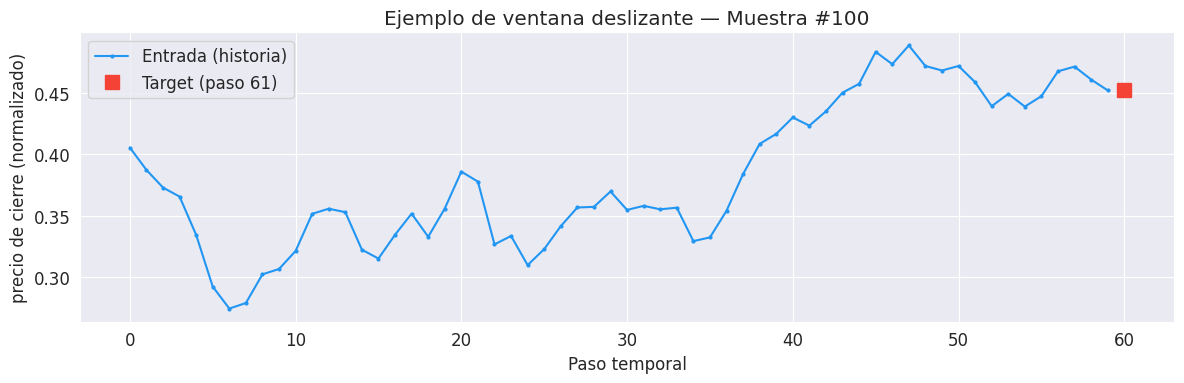

In [ ]:
# ============================================================
# 🪟 Creación de ventanas deslizantes — Cobre
# ============================================================
WINDOW_C = 60   # 60 días hábiles ≈ 3 meses de historia
HORIZON_C = 1        # Predecir 1 paso adelante (1 día hábil)

X_train_c, y_train_c = create_sequences(train_scaled_c, WINDOW_C, HORIZON_C)
X_test_c, y_test_c = create_sequences(test_scaled_c, WINDOW_C, HORIZON_C)

# Objetivo del modelo: predecir la VARIACIÓN respecto al último valor de la ventana (el modelo aprende una corrección sobre el naive)
PREDECIR_DELTA_C = True
if PREDECIR_DELTA_C:
    base_train_c = X_train_c[:, -1, 0]   # último valor conocido de cada ventana
    base_test_c = X_test_c[:, -1, 0]
else:
    base_train_c = np.zeros(len(X_train_c))
    base_test_c = np.zeros(len(X_test_c))
y_train_fit_c = y_train_c - base_train_c   # lo que realmente aprende el modelo

print(f'Ventana: {WINDOW_C} pasos (60 días hábiles ≈ 3 meses de historia) → Predecir: {HORIZON_C} paso')
print(f'\nShapes multivariados:')
print(f'  X_train: {X_train_c.shape}  (muestras, {WINDOW_C} pasos, {len(selected_features_c)} features)')
print(f'  y_train: {y_train_c.shape}  (predecir solo precio de cierre)')
print(f'  X_test:  {X_test_c.shape}')
print(f'  y_test:  {y_test_c.shape}')
print(f'\nObjetivo del modelo: {"variación respecto al último valor" if PREDECIR_DELTA_C else "valor normalizado del siguiente paso"}')

# Visualizar una ventana de ejemplo
fig, ax = plt.subplots(figsize=(12, 4))
sample_idx = 100
window = X_train_c[sample_idx, :, 0]
target = y_train_c[sample_idx]
ax.plot(range(WINDOW_C), window, 'o-', color=COLORS['lstm'],
        markersize=2, label='Entrada (historia)')
ax.plot(WINDOW_C, target, 's', color=COLORS['rnn'],
        markersize=10, label=f'Target (paso {WINDOW_C+1})')
ax.set_xlabel('Paso temporal')
ax.set_ylabel('precio de cierre (normalizado)')
ax.set_title(f'Ejemplo de ventana deslizante — Muestra #{sample_idx}')
ax.legend()
plt.tight_layout()
plt.show()


In [ ]:
# ============================================================
# 🏗️ Modelo LSTM Stacked (apilado) — Cobre
# ============================================================
tf.random.set_seed(42)

model_lstm_c = models.Sequential([
    layers.LSTM(128, return_sequences=True,
                input_shape=(WINDOW_C, len(selected_features_c)),
                name='lstm_128'),
    layers.Dropout(0.3, name='drop_1'),
    layers.LSTM(64, name='lstm_64'),
    layers.Dropout(0.2, name='drop_2'),
    layers.Dense(32, activation='relu', name='dense_32'),
    layers.Dense(1, name='salida')
], name='LSTM_Stacked_Cobre')

model_lstm_c.compile(optimizer='adam', loss='mse', metrics=['mae'])

print('=== LSTM Stacked — Cobre ===')
model_lstm_c.summary()
lstm_params_c = model_lstm_c.count_params()
print(f'\nTotal parámetros: {lstm_params_c:,}')


=== LSTM Stacked — Cobre ===


Model: "LSTM_Stacked_Cobre"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_128 (LSTM)                 │ (None, 60, 128)        │        68,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop_1 (Dropout)                │ (None, 60, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_64 (LSTM)                  │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop_2 (Dropout)                │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_32 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida (Dense)                  │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 120,129 (469.25 KB)

 Trainable params: 120,129 (469.25 KB)

 Non-trainable params: 0 (0.00 B)


Total parámetros: 120,129


In [ ]:
# ============================================================
# 🏗️ Modelo GRU Stacked (apilado) — Cobre
# ============================================================
tf.random.set_seed(42)

model_gru_c = models.Sequential([
    layers.GRU(128, return_sequences=True,
               input_shape=(WINDOW_C, len(selected_features_c)),
               name='gru_128'),
    layers.Dropout(0.3, name='drop_1'),
    layers.GRU(64, name='gru_64'),
    layers.Dropout(0.2, name='drop_2'),
    layers.Dense(32, activation='relu', name='dense_32'),
    layers.Dense(1, name='salida')
], name='GRU_Stacked_Cobre')

model_gru_c.compile(optimizer='adam', loss='mse', metrics=['mae'])

print('=== GRU Stacked — Cobre ===')
model_gru_c.summary()
gru_params_c = model_gru_c.count_params()
print(f'\nTotal parámetros: {gru_params_c:,}')
print(f'\n📊 Diferencia: LSTM tiene {lstm_params_c - gru_params_c:,} parámetros más que GRU')
print(f'   GRU es {(1 - gru_params_c/lstm_params_c)*100:.1f}% más ligero')


=== GRU Stacked — Cobre ===


Model: "GRU_Stacked_Cobre"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru_128 (GRU)                   │ (None, 60, 128)        │        51,840 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop_1 (Dropout)                │ (None, 60, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_64 (GRU)                    │ (None, 64)             │        37,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop_2 (Dropout)                │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_32 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida (Dense)                  │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 91,201 (356.25 KB)

 Trainable params: 91,201 (356.25 KB)

 Non-trainable params: 0 (0.00 B)


Total parámetros: 91,201

📊 Diferencia: LSTM tiene 28,928 parámetros más que GRU
   GRU es 24.1% más ligero


In [ ]:
# ============================================================
# 🚀 Entrenamiento de ambos modelos — Cobre
# ============================================================
EPOCHS = 30
BATCH_SIZE = 64

cb_factory = lambda: [
    callbacks.EarlyStopping(patience=5, restore_best_weights=True, verbose=0),
    callbacks.ReduceLROnPlateau(factor=0.5, patience=3, verbose=0)
]

# Entrenar LSTM
print('🔵 Entrenando LSTM Stacked...')
t0 = time.time()
hist_lstm_c = model_lstm_c.fit(
    X_train_c, y_train_fit_c,
    epochs=EPOCHS, batch_size=BATCH_SIZE,
    validation_split=0.15, callbacks=cb_factory(), verbose=0
)
time_lstm_c = time.time() - t0
print(f'   ⏱️ {time_lstm_c:.1f}s | Épocas: {len(hist_lstm_c.history["loss"])} | Mejor val_loss: {min(hist_lstm_c.history["val_loss"]):.6f}')

# Entrenar GRU
print('🟠 Entrenando GRU Stacked...')
t0 = time.time()
hist_gru_c = model_gru_c.fit(
    X_train_c, y_train_fit_c,
    epochs=EPOCHS, batch_size=BATCH_SIZE,
    validation_split=0.15, callbacks=cb_factory(), verbose=0
)
time_gru_c = time.time() - t0
print(f'   ⏱️ {time_gru_c:.1f}s | Épocas: {len(hist_gru_c.history["loss"])} | Mejor val_loss: {min(hist_gru_c.history["val_loss"]):.6f}')

print(f'\n⚡ GRU fue {time_lstm_c/time_gru_c:.1f}x más rápido que LSTM')


🔵 Entrenando LSTM Stacked...
   ⏱️ 13.1s | Épocas: 19 | Mejor val_loss: 0.000492
🟠 Entrenando GRU Stacked...
   ⏱️ 8.2s | Épocas: 10 | Mejor val_loss: 0.000491

⚡ GRU fue 1.6x más rápido que LSTM


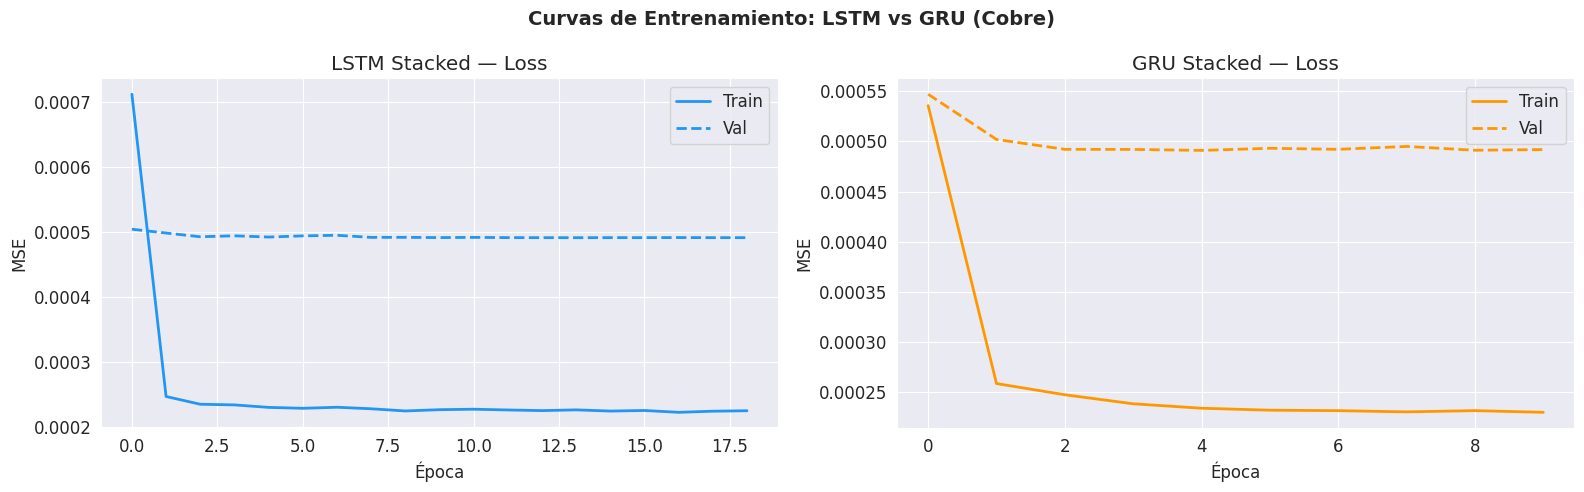

In [ ]:
# ============================================================
# 📉 Curvas de entrenamiento — LSTM vs GRU — Cobre
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# LSTM
axes[0].plot(hist_lstm_c.history['loss'], color=COLORS['lstm'],
             label='Train', linewidth=2)
axes[0].plot(hist_lstm_c.history['val_loss'], color=COLORS['lstm'],
             linestyle='--', label='Val', linewidth=2)
axes[0].set_title('LSTM Stacked — Loss')
axes[0].set_xlabel('Época')
axes[0].set_ylabel('MSE')
axes[0].legend()

# GRU
axes[1].plot(hist_gru_c.history['loss'], color=COLORS['gru'],
             label='Train', linewidth=2)
axes[1].plot(hist_gru_c.history['val_loss'], color=COLORS['gru'],
             linestyle='--', label='Val', linewidth=2)
axes[1].set_title('GRU Stacked — Loss')
axes[1].set_xlabel('Época')
axes[1].set_ylabel('MSE')
axes[1].legend()

plt.suptitle('Curvas de Entrenamiento: LSTM vs GRU (Cobre)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


In [ ]:
# ============================================================
# 🏗️ Modelos univariados de referencia (LSTM y GRU simples) — Cobre
# ============================================================
# Misma arquitectura del Ejemplo 1: una sola capa de 64 unidades + Dropout.
# Usan SOLO la variable objetivo (columna 0) para comparar contra el multivariado.
X_train_u_c = X_train_c[:, :, :1]
X_test_u_c = X_test_c[:, :, :1]

uni_models_c = {}
for kind, Layer in [('LSTM', layers.LSTM), ('GRU', layers.GRU)]:
    tf.random.set_seed(42)
    m_uni = models.Sequential([
        Layer(64, input_shape=(WINDOW_C, 1), name=f'{kind.lower()}_64'),
        layers.Dropout(0.2, name='dropout'),
        layers.Dense(1, name='salida')
    ], name=f'{kind}_Basico_Cobre')
    m_uni.compile(optimizer='adam', loss='mse', metrics=['mae'])

    print(f'Entrenando {kind} univariado...')
    t0 = time.time()
    h_uni = m_uni.fit(
        X_train_u_c, y_train_fit_c,
        epochs=EPOCHS, batch_size=BATCH_SIZE,
        validation_split=0.15, callbacks=cb_factory(), verbose=0
    )
    uni_models_c[kind] = {
        'model': m_uni, 'history': h_uni,
        'time': time.time() - t0, 'params': m_uni.count_params()
    }
    print(f'   ⏱️ {uni_models_c[kind]["time"]:.1f}s | Params: {uni_models_c[kind]["params"]:,}')


Entrenando LSTM univariado...
   ⏱️ 13.8s | Params: 16,961
Entrenando GRU univariado...
   ⏱️ 15.9s | Params: 12,929


In [ ]:
# ============================================================
# 📏 Comparación: Naive vs LSTM vs GRU (uni y multivariado) — Cobre
# ============================================================

# Predicciones multivariadas
pred_lstm_m_c = model_lstm_c.predict(X_test_c, verbose=0).flatten() + base_test_c
pred_gru_m_c = model_gru_c.predict(X_test_c, verbose=0).flatten() + base_test_c

# Predicciones univariadas
pred_lstm_u_c = uni_models_c['LSTM']['model'].predict(X_test_u_c, verbose=0).flatten() + base_test_c
pred_gru_u_c = uni_models_c['GRU']['model'].predict(X_test_u_c, verbose=0).flatten() + base_test_c

# Baseline naive: predecir el último valor conocido de la ventana
y_naive_c = X_test_c[:, -1, 0]

# Desnormalizar para métricas interpretables
y_test_real_c = denorm_c(y_test_c)
pred_lstm_real_c = denorm_c(pred_lstm_m_c)
pred_gru_real_c = denorm_c(pred_gru_m_c)
pred_lstm_u_real_c = denorm_c(pred_lstm_u_c)
pred_gru_u_real_c = denorm_c(pred_gru_u_c)
y_naive_real_c = denorm_c(y_naive_c)

# Métricas
res_c = {
    'Naive':             {**evaluate_forecast(y_test_real_c, y_naive_real_c),      'params': 0, 'time': 0.0},
    'LSTM Univariado':   {**evaluate_forecast(y_test_real_c, pred_lstm_u_real_c), 'params': uni_models_c['LSTM']['params'], 'time': uni_models_c['LSTM']['time']},
    'GRU Univariado':    {**evaluate_forecast(y_test_real_c, pred_gru_u_real_c),  'params': uni_models_c['GRU']['params'], 'time': uni_models_c['GRU']['time']},
    'LSTM Multivariado': {**evaluate_forecast(y_test_real_c, pred_lstm_real_c),   'params': lstm_params_c, 'time': time_lstm_c},
    'GRU Multivariado':  {**evaluate_forecast(y_test_real_c, pred_gru_real_c),    'params': gru_params_c, 'time': time_gru_c},
}

print('=' * 88)
print('COMPARACIÓN Cobre: Naive vs LSTM vs GRU')
print('=' * 88)
print(f'{"":<20} {"MAE (USD/lb)":<14} {"RMSE (USD/lb)":<14} {"MAPE (%)":<12} {"Params":<10} {"Tiempo (s)":<10}')
print('-' * 88)
for name, r in res_c.items():
    print(f'{name:<20} {r["MAE"]:<14.4f} {r["RMSE"]:<14.4f} {r["MAPE"]:<12.2f} {r["params"]:<10,} {r["time"]:<10.1f}')
print('-' * 88)

naive_mae_c = res_c['Naive']['MAE']
print('\nMejora del MAE respecto al baseline naive:')
for name, r in res_c.items():
    if name != 'Naive':
        print(f'   {name:<20} {(1 - r["MAE"] / naive_mae_c) * 100:+.1f}%')


COMPARACIÓN Cobre: Naive vs LSTM vs GRU
                     MAE (USD/lb)   RMSE (USD/lb)  MAPE (%)     Params     Tiempo (s)
----------------------------------------------------------------------------------------
Naive                0.0617         0.0963         1.23         0          0.0       
LSTM Univariado      0.0619         0.0964         1.23         16,961     13.8      
GRU Univariado       0.0624         0.0966         1.24         12,929     15.9      
LSTM Multivariado    0.0619         0.0964         1.23         120,129    13.1      
GRU Multivariado     0.0623         0.0966         1.24         91,201     8.2       
----------------------------------------------------------------------------------------

Mejora del MAE respecto al baseline naive:
   LSTM Univariado      -0.4%
   GRU Univariado       -1.1%
   LSTM Multivariado    -0.3%
   GRU Multivariado     -1.0%


Experimentando con diferentes tamaños de ventana (GRU)...
  Ventana= 20 pasos (~1 m) | MAE: 0.0612 USD/lb | Tiempo: 3.8s | Params: 13,697
  Ventana= 60 pasos (~3 m) | MAE: 0.0619 USD/lb | Tiempo: 5.8s | Params: 13,697
  Ventana=120 pasos (~6 m) | MAE: 0.0654 USD/lb | Tiempo: 3.3s | Params: 13,697


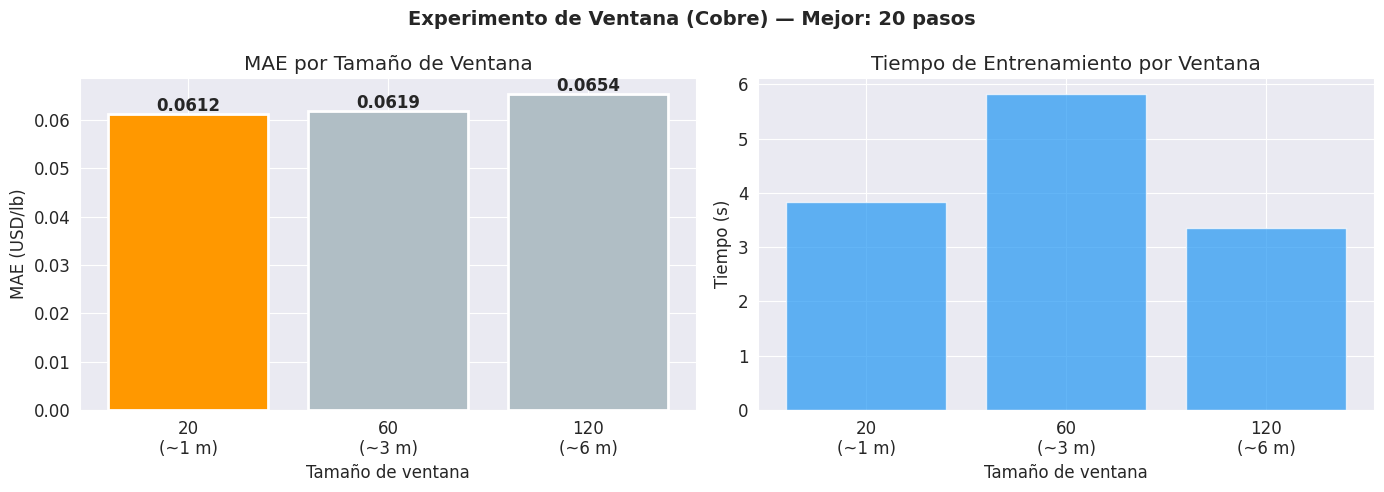

In [ ]:
# ============================================================
# 🔍 Experimento: Tamaño de ventana óptimo — Cobre
# ============================================================
windows = [20, 60, 120]  # ~1, 3 y 6 meses
window_results_c = {}

print('Experimentando con diferentes tamaños de ventana (GRU)...')
for w in windows:
    tf.random.set_seed(42)

    X_tr, y_tr = create_sequences(train_scaled_c, w, 1)
    X_te, y_te = create_sequences(test_scaled_c, w, 1)
    base_tr = X_tr[:, -1, 0] if PREDECIR_DELTA_C else 0
    base_te = X_te[:, -1, 0] if PREDECIR_DELTA_C else 0

    m = models.Sequential([
        layers.GRU(64, input_shape=(w, len(selected_features_c))),
        layers.Dropout(0.2),
        layers.Dense(1)
    ])
    m.compile(optimizer='adam', loss='mse', metrics=['mae'])

    t0 = time.time()
    m.fit(X_tr, y_tr - base_tr, epochs=20, batch_size=64,
          validation_split=0.15, verbose=0,
          callbacks=[callbacks.EarlyStopping(patience=3,
                     restore_best_weights=True, verbose=0)])
    elapsed = time.time() - t0

    pred = m.predict(X_te, verbose=0).flatten() + base_te
    pred_real = denorm_c(pred)
    y_real = denorm_c(y_te)

    mae = mean_absolute_error(y_real, pred_real)
    window_results_c[w] = {'MAE': mae, 'time': elapsed, 'params': m.count_params()}
    print(f'  Ventana={w:>3} pasos ({f'~{w/21:.0f} m'}) | MAE: {mae:.4f} USD/lb | Tiempo: {elapsed:.1f}s | Params: {m.count_params():,}')

# Gráfico de comparación
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

w_labels = [f'{w}\n(' + f'~{w/21:.0f} m' + ')' for w in windows]
maes = [window_results_c[w]['MAE'] for w in windows]
times = [window_results_c[w]['time'] for w in windows]

colors_bar = [COLORS['gru'] if m == min(maes) else '#B0BEC5' for m in maes]
axes[0].bar(w_labels, maes, color=colors_bar, edgecolor='white', linewidth=2)
axes[0].set_ylabel('MAE (USD/lb)')
axes[0].set_xlabel('Tamaño de ventana')
axes[0].set_title('MAE por Tamaño de Ventana')
for i, v in enumerate(maes):
    axes[0].text(i, v * 1.01, f'{v:.4f}', ha='center', fontweight='bold')

axes[1].bar(w_labels, times, color=COLORS['lstm'], alpha=0.7, edgecolor='white')
axes[1].set_ylabel('Tiempo (s)')
axes[1].set_xlabel('Tamaño de ventana')
axes[1].set_title('Tiempo de Entrenamiento por Ventana')

best_w_c = min(window_results_c, key=lambda k: window_results_c[k]['MAE'])
plt.suptitle(f'Experimento de Ventana (Cobre) — Mejor: {best_w_c} pasos',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


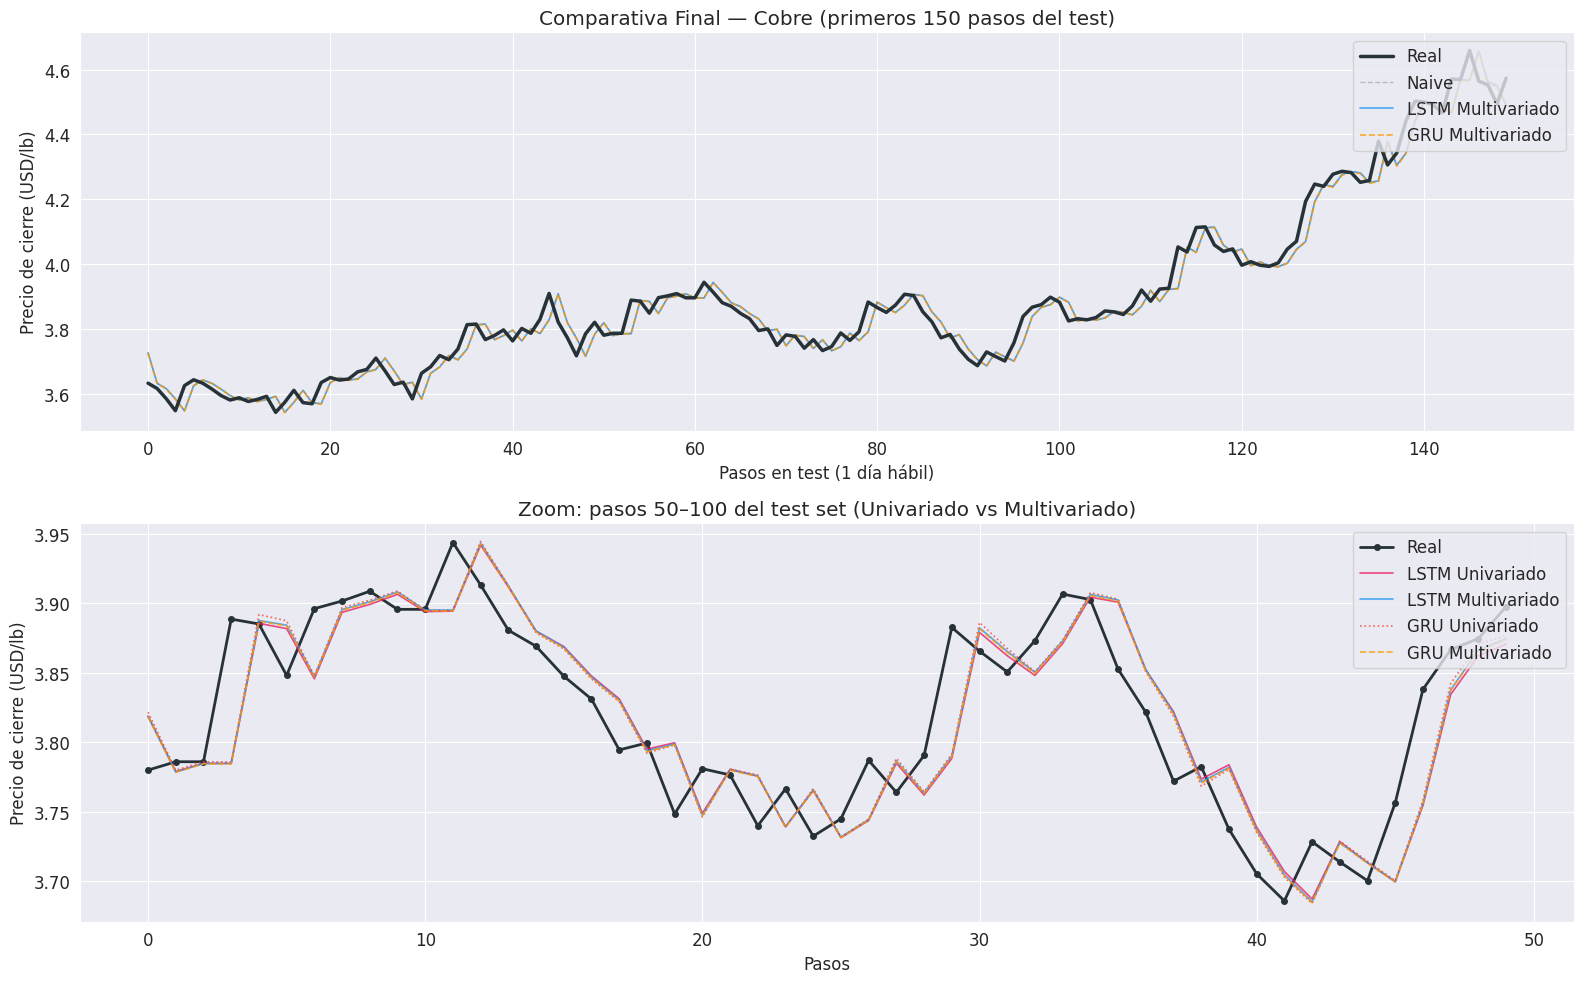

In [ ]:
# ============================================================
# 📊 Visualización final comparativa — Cobre
# ============================================================
fig, axes = plt.subplots(2, 1, figsize=(16, 10))

# Subplot 1: primeros pasos del test
n_show = 150
axes[0].plot(y_test_real_c[:n_show], color=COLORS['actual'],
             linewidth=2.5, label='Real', zorder=5)
axes[0].plot(y_naive_real_c[:n_show], color=COLORS['naive'],
             linewidth=1, linestyle='--', alpha=0.6, label='Naive')
axes[0].plot(pred_lstm_real_c[:n_show], color=COLORS['lstm'],
             linewidth=1.2, alpha=0.8, label='LSTM Multivariado')
axes[0].plot(pred_gru_real_c[:n_show], color=COLORS['gru'],
             linewidth=1.2, alpha=0.8, label='GRU Multivariado', linestyle='--')
axes[0].set_xlabel('Pasos en test (1 día hábil)')
axes[0].set_ylabel('Precio de cierre (USD/lb)')
axes[0].set_title(f'Comparativa Final — Cobre (primeros {n_show} pasos del test)')
axes[0].legend(loc='upper right')

# Subplot 2: Univariado vs Multivariado (zoom)
n_zoom = 50
start = 50
rng = range(n_zoom)
axes[1].plot(rng, y_test_real_c[start:start+n_zoom], 'o-', color=COLORS['actual'],
             linewidth=2, markersize=4, label='Real')
axes[1].plot(rng, pred_lstm_u_real_c[start:start+n_zoom], color=COLORS['pred'],
             linewidth=1.2, alpha=0.8, label='LSTM Univariado')
axes[1].plot(rng, pred_lstm_real_c[start:start+n_zoom], color=COLORS['lstm'],
             linewidth=1.2, alpha=0.8, label='LSTM Multivariado')
axes[1].plot(rng, pred_gru_u_real_c[start:start+n_zoom], color=COLORS['rnn'],
             linewidth=1.2, alpha=0.8, label='GRU Univariado', linestyle=':')
axes[1].plot(rng, pred_gru_real_c[start:start+n_zoom], color=COLORS['gru'],
             linewidth=1.2, alpha=0.8, label='GRU Multivariado', linestyle='--')
axes[1].set_xlabel('Pasos')
axes[1].set_ylabel('Precio de cierre (USD/lb)')
axes[1].set_title(f'Zoom: pasos {start}–{start+n_zoom} del test set (Univariado vs Multivariado)')
axes[1].legend(loc='upper right')

plt.tight_layout()
plt.show()


In [ ]:
# ============================================================
# 🧾 Resumen automático de resultados — Cobre
# ============================================================
modelos_rnn_c = ['LSTM Univariado', 'GRU Univariado', 'LSTM Multivariado', 'GRU Multivariado']
mejor_c = min(modelos_rnn_c, key=lambda k: res_c[k]['MAE'])
mejora_c = (1 - res_c[mejor_c]['MAE'] / res_c['Naive']['MAE']) * 100

print(f'🏆 Mejor modelo en Cobre (menor MAE): {mejor_c}')
print(f'   MAE = {res_c[mejor_c]["MAE"]:.4f} USD/lb ({mejora_c:+.1f}% vs naive)')

lstm_mae = res_c['LSTM Multivariado']['MAE']
gru_mae = res_c['GRU Multivariado']['MAE']
ganador = 'GRU' if gru_mae < lstm_mae else 'LSTM'
print(f'\n⚖️ Multivariado: {ganador} gana por {abs(lstm_mae - gru_mae):.4f} USD/lb de MAE')
print(f'⚡ GRU entrenó {time_lstm_c/time_gru_c:.1f}x más rápido y usa {(1 - gru_params_c/lstm_params_c)*100:.1f}% menos parámetros')

for kind in ['LSTM', 'GRU']:
    uni, multi = res_c[f'{kind} Univariado']['MAE'], res_c[f'{kind} Multivariado']['MAE']
    print(f'📐 {kind}: multivariado {"mejora" if multi < uni else "NO mejora"} al univariado ({uni:.4f} → {multi:.4f} USD/lb)')

if mejora_c <= 0:
    print('\n⚠️ Ningún modelo supera al baseline naive en este dataset.')


🏆 Mejor modelo en Cobre (menor MAE): LSTM Multivariado
   MAE = 0.0619 USD/lb (-0.3% vs naive)

⚖️ Multivariado: LSTM gana por 0.0004 USD/lb de MAE
⚡ GRU entrenó 1.6x más rápido y usa 24.1% menos parámetros
📐 LSTM: multivariado mejora al univariado (0.0619 → 0.0619 USD/lb)
📐 GRU: multivariado mejora al univariado (0.0624 → 0.0623 USD/lb)

⚠️ Ningún modelo supera al baseline naive en este dataset.


### 💡 Conclusiones — Cobre

> _Completa esta sección con los resultados que obtuviste al ejecutar el notebook (puedes apoyarte en la celda de resumen automático)._

1. **¿Qué modelo rindió mejor, LSTM o GRU?** _(MAE, RMSE y diferencia entre ambos)_
2. **¿Superaron al baseline naive?** _(porcentaje de mejora del MAE; si no lo superaron, explica por qué)_
3. **Univariado vs multivariado:** _(Apertura, máximo y mínimo son casi idénticos al cierre: ¿aportaron algo nuevo? ¿Y el volumen?)_
4. **Tamaño de ventana:** _(¿cuál fue la mejor ventana? ¿ventanas más largas ayudaron o solo costaron más tiempo?)_
5. **Eficiencia:** _(parámetros y tiempo de entrenamiento de GRU frente a LSTM)_

> ⚡ **Pregunta para reflexionar:** ¿Se puede predecir de forma útil el precio de un commodity solo con su historial? ¿Qué otras variables (dólar, inventarios, demanda de China) podrían ayudar?

TABLA FINAL — 2 datasets × (Naive + LSTM/GRU univariado + LSTM/GRU multivariado)
Dataset            Modelo Unidad  Params  Tiempo (s)       MAE      RMSE  Mejora MAE vs naive (%)
  Solar             Naive     kW       0         0.0 1178.6384 2228.3897                   0.0000
  Solar   LSTM Univariado     kW   16961        12.7 1278.4767 2197.2128                  -8.4706
  Solar    GRU Univariado     kW   12929        12.2 1276.3842 2133.8098                  -8.2931
  Solar LSTM Multivariado     kW  119617        18.7 1382.5162 2336.0925                 -17.2977
  Solar  GRU Multivariado     kW   90817        17.2 1146.3654 2133.7734                   2.7382
  Cobre             Naive USD/lb       0         0.0    0.0617    0.0963                   0.0000
  Cobre   LSTM Univariado USD/lb   16961        13.8    0.0619    0.0964                  -0.3955
  Cobre    GRU Univariado USD/lb   12929        15.9    0.0624    0.0966                  -1.1493
  Cobre LSTM Multivariado USD/lb  120

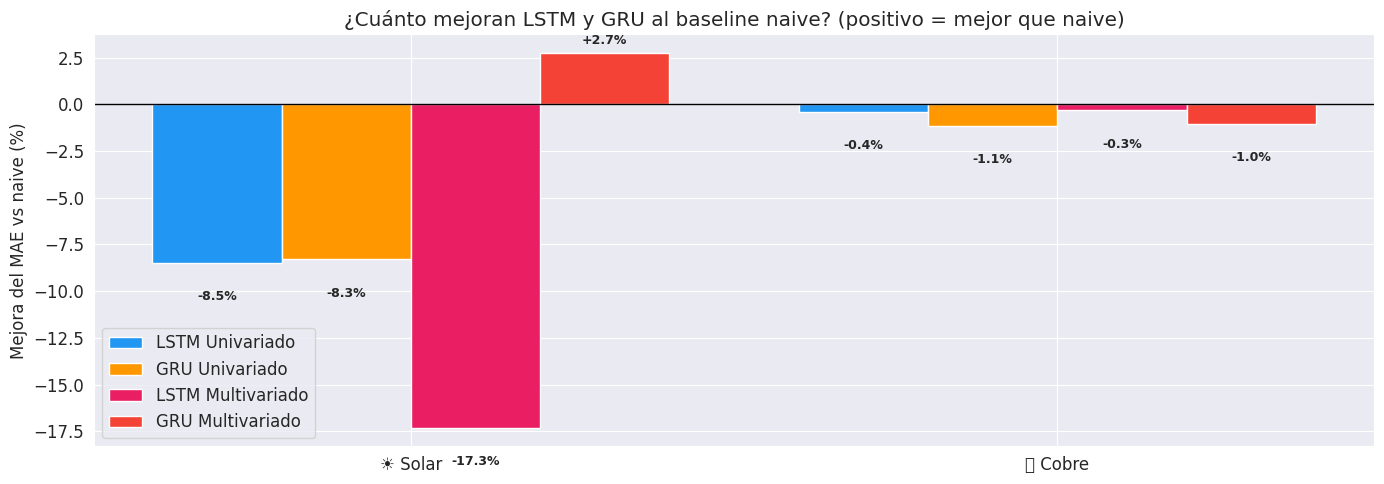

In [ ]:
# ============================================================
# 🏁 Comparación final entre datasets
# ============================================================
filas = []
for dataset, res, unidad in [('Solar', res_s, 'kW'), ('Cobre', res_c, 'USD/lb')]:
    for modelo, r in res.items():
        filas.append({
            'Dataset': dataset, 'Modelo': modelo, 'Unidad': unidad,
            'Params': r['params'], 'Tiempo (s)': round(r['time'], 1),
            'MAE': r['MAE'], 'RMSE': r['RMSE'],
            'Mejora MAE vs naive (%)': (1 - r['MAE'] / res['Naive']['MAE']) * 100
        })

df_final = pd.DataFrame(filas)
print('=' * 100)
print('TABLA FINAL — 2 datasets × (Naive + LSTM/GRU univariado + LSTM/GRU multivariado)')
print('=' * 100)
print(df_final.round(4).to_string(index=False))

# Gráfico: mejora respecto al naive (el MAE está en unidades distintas, por eso se usa % de mejora)
fig, ax = plt.subplots(figsize=(14, 5))
modelos_plot = ['LSTM Univariado', 'GRU Univariado', 'LSTM Multivariado', 'GRU Multivariado']
bar_colors = [COLORS['lstm'], COLORS['gru'], COLORS['pred'], COLORS['rnn']]
x = np.arange(2)
ancho = 0.2
for i, (modelo, color) in enumerate(zip(modelos_plot, bar_colors)):
    vals = [df_final[(df_final.Dataset == d) & (df_final.Modelo == modelo)]['Mejora MAE vs naive (%)'].values[0]
            for d in ['Solar', 'Cobre']]
    bars = ax.bar(x + (i - 1.5) * ancho, vals, ancho, label=modelo, color=color, edgecolor='white')
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + (0.5 if v >= 0 else -2), f'{v:+.1f}%',
                ha='center', fontsize=9, fontweight='bold')
ax.axhline(0, color='black', linewidth=1)
ax.set_xticks(x)
ax.set_xticklabels(['☀️ Solar', '🔶 Cobre'])
ax.set_ylabel('Mejora del MAE vs naive (%)')
ax.set_title('¿Cuánto mejoran LSTM y GRU al baseline naive? (positivo = mejor que naive)')
ax.legend()
plt.tight_layout()
plt.show()


---

## 🔬 Ejemplo 3 (Avanzado): Clasificación de Señales — Benchmark RNN/LSTM/GRU/BiLSTM

**Objetivo:** Comparar las 4 arquitecturas recurrentes en una tarea de **clasificación de secuencias**, usando un dataset sintético de formas de onda.

**Cambio de paradigma:** En los Ejemplos 1 y 2 hicimos **forecasting** (many-to-one con salida continua). Ahora hacemos **clasificación** (many-to-one con salida categórica).

**¿Por qué Bidirectional?** En clasificación, tenemos **toda la secuencia disponible** antes de decidir. A diferencia del forecasting (donde no podemos mirar el futuro), aquí BiLSTM puede leer la señal en ambas direcciones.

**Dataset:** 5 tipos de señales sintéticas (5000 muestras, 128 timesteps cada una).

| Clase | Señal | Característica |
|---|---|---|
| 0 | Sinusoidal | Frecuencia y fase variables |
| 1 | Cuadrada | Transiciones abruptas |
| 2 | Diente de Sierra | Rampas lineales |
| 3 | Chirp | Frecuencia que aumenta en el tiempo |
| 4 | Ruido Gaussiano | Sin patrón periódico |

In [ ]:
# ============================================================
# 🎵 Generación del dataset de señales sintéticas
# ============================================================
np.random.seed(42)

N_SAMPLES = 1000      # Muestras por clase
SEQ_LEN = 128         # Longitud de cada señal
N_CLASSES = 5
NOISE_LEVEL = 0.05    # Ruido añadido

class_names = ['Sinusoidal', 'Cuadrada', 'Diente de Sierra', 'Chirp', 'Ruido']
t = np.linspace(0, 1, SEQ_LEN)

signals = []
labels = []

for i in range(N_SAMPLES):
    # Clase 0: Sinusoidal (freq aleatoria 1-3 Hz, fase aleatoria)
    freq = np.random.uniform(1, 3)
    phase = np.random.uniform(0, 2 * np.pi)
    s = np.sin(2 * np.pi * freq * t + phase)
    signals.append(s + np.random.normal(0, NOISE_LEVEL, SEQ_LEN))
    labels.append(0)

    # Clase 1: Cuadrada
    freq = np.random.uniform(1, 3)
    phase = np.random.uniform(0, 2 * np.pi)
    s = np.sign(np.sin(2 * np.pi * freq * t + phase))
    signals.append(s + np.random.normal(0, NOISE_LEVEL, SEQ_LEN))
    labels.append(1)

    # Clase 2: Diente de Sierra (sawtooth)
    freq = np.random.uniform(1, 3)
    phase = np.random.uniform(0, 1)
    s = 2 * ((freq * t + phase) % 1) - 1
    signals.append(s + np.random.normal(0, NOISE_LEVEL, SEQ_LEN))
    labels.append(2)

    # Clase 3: Chirp (frecuencia creciente de f0 a f1)
    f0 = np.random.uniform(0.5, 1.5)
    f1 = np.random.uniform(3, 6)
    s = np.sin(2 * np.pi * (f0 * t + (f1 - f0) * t**2 / 2))
    signals.append(s + np.random.normal(0, NOISE_LEVEL, SEQ_LEN))
    labels.append(3)

    # Clase 4: Ruido Gaussiano (sin estructura)
    amplitude = np.random.uniform(0.5, 1.5)
    s = np.random.normal(0, amplitude, SEQ_LEN)
    signals.append(s)
    labels.append(4)

X_signals = np.array(signals)
y_signals = np.array(labels)

print(f'Dataset de señales:')
print(f'  X shape: {X_signals.shape}')
print(f'  Clases: {N_CLASSES} ({", ".join(class_names)})')
print(f'  Muestras por clase: {N_SAMPLES}')
print(f'  Total: {len(X_signals)} señales de {SEQ_LEN} timesteps')

Dataset de señales:
  X shape: (5000, 128)
  Clases: 5 (Sinusoidal, Cuadrada, Diente de Sierra, Chirp, Ruido)
  Muestras por clase: 1000
  Total: 5000 señales de 128 timesteps


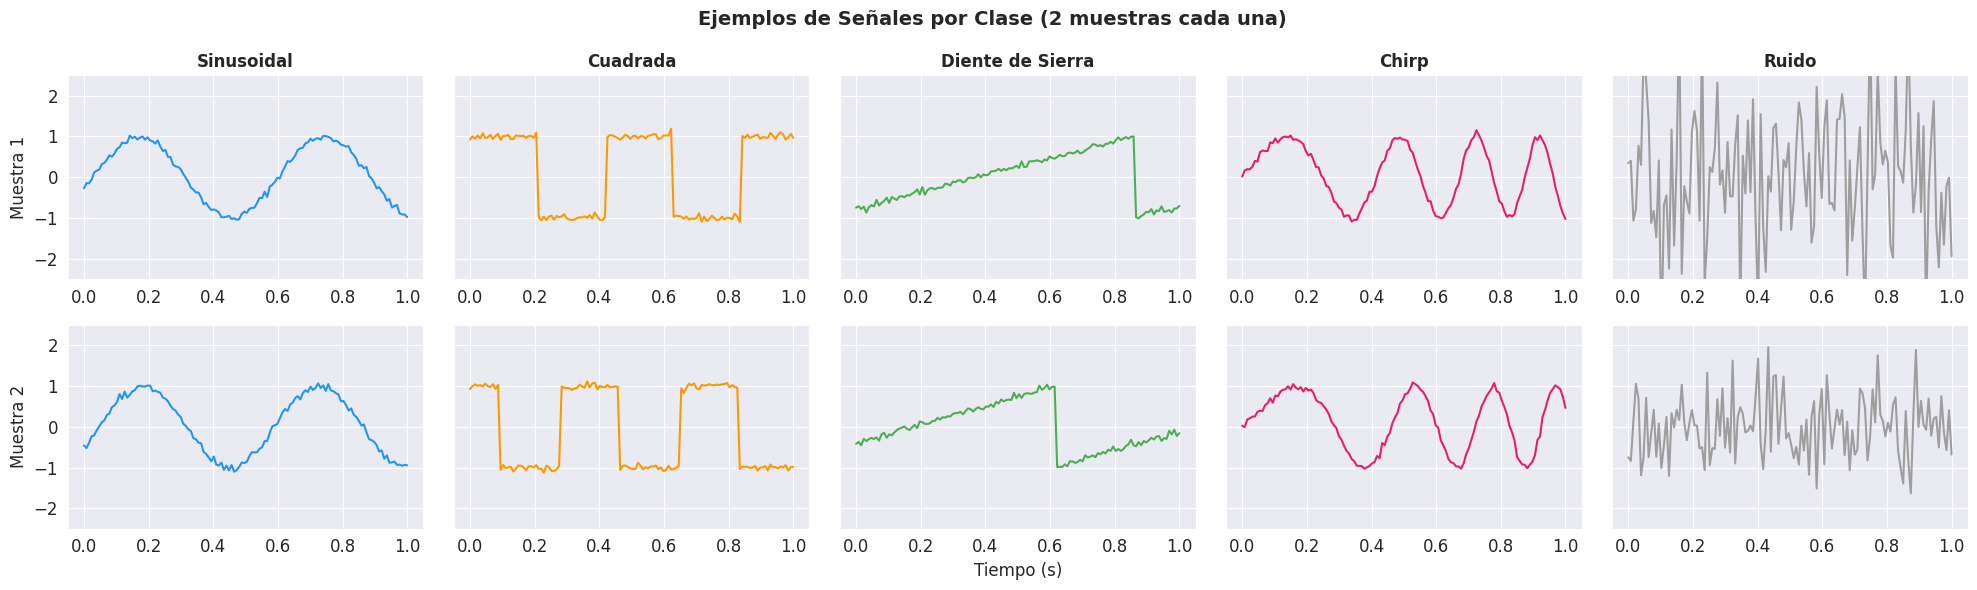

In [ ]:
# ============================================================
# 📊 Visualización de señales por clase
# ============================================================
fig, axes = plt.subplots(2, 5, figsize=(20, 6))
class_colors = ['#2196F3', '#FF9800', '#4CAF50', '#E91E63', '#9E9E9E']

for cls in range(N_CLASSES):
    cls_indices = np.where(y_signals == cls)[0][:2]  # 2 muestras por clase
    for row, idx in enumerate(cls_indices):
        ax = axes[row, cls]
        ax.plot(t, X_signals[idx], color=class_colors[cls], linewidth=1.5)
        if row == 0:
            ax.set_title(class_names[cls], fontweight='bold', fontsize=12)
        ax.set_ylim(-2.5, 2.5)
        if cls == 0:
            ax.set_ylabel(f'Muestra {row+1}')
        else:
            ax.set_yticklabels([])

axes[1, 2].set_xlabel('Tiempo (s)')
fig.suptitle('Ejemplos de Señales por Clase (2 muestras cada una)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# 🔧 Preparación de datos para clasificación
# ============================================================
from sklearn.model_selection import train_test_split as tts

# Normalizar señales con StandardScaler
scaler_sig = StandardScaler()
X_norm = scaler_sig.fit_transform(X_signals)

# Reshape a (samples, timesteps, 1) para las RNN
X_norm = X_norm.reshape(-1, SEQ_LEN, 1)

# Split estratificado 80/20
X_train_sig, X_test_sig, y_train_sig, y_test_sig = tts(
    X_norm, y_signals, test_size=0.2,
    stratify=y_signals, random_state=42
)

# One-hot encoding
y_train_oh = tf.keras.utils.to_categorical(y_train_sig, N_CLASSES)
y_test_oh = tf.keras.utils.to_categorical(y_test_sig, N_CLASSES)

print(f'Datos de entrenamiento:')
print(f'  X_train: {X_train_sig.shape}')
print(f'  y_train: {y_train_oh.shape}')
print(f'\nDatos de test:')
print(f'  X_test: {X_test_sig.shape}')
print(f'  y_test: {y_test_oh.shape}')
print(f'\nDistribución de clases (train):')
for cls in range(N_CLASSES):
    n = np.sum(y_train_sig == cls)
    print(f'  {class_names[cls]}: {n} ({n/len(y_train_sig)*100:.1f}%)')

Datos de entrenamiento:
  X_train: (4000, 128, 1)
  y_train: (4000, 5)

Datos de test:
  X_test: (1000, 128, 1)
  y_test: (1000, 5)

Distribución de clases (train):
  Sinusoidal: 800 (20.0%)
  Cuadrada: 800 (20.0%)
  Diente de Sierra: 800 (20.0%)
  Chirp: 800 (20.0%)
  Ruido: 800 (20.0%)


In [ ]:
# ============================================================
# 🏗️ Definición de los 4 modelos recurrentes
# ============================================================

def build_classifier(model_type, input_shape=(SEQ_LEN, 1), n_classes=N_CLASSES):
    '''Construye un clasificador recurrente.

    Args:
        model_type: 'SimpleRNN', 'LSTM', 'GRU' o 'BiLSTM'
        input_shape: forma de entrada (timesteps, features)
        n_classes: número de clases
    '''
    tf.random.set_seed(42)
    model = models.Sequential(name=model_type)

    if model_type == 'SimpleRNN':
        model.add(layers.SimpleRNN(64, input_shape=input_shape))
    elif model_type == 'LSTM':
        model.add(layers.LSTM(64, input_shape=input_shape))
    elif model_type == 'GRU':
        model.add(layers.GRU(64, input_shape=input_shape))
    elif model_type == 'BiLSTM':
        model.add(layers.Bidirectional(
            layers.LSTM(64), input_shape=input_shape
        ))

    model.add(layers.Dense(32, activation='relu'))
    model.add(layers.Dropout(0.3))
    model.add(layers.Dense(n_classes, activation='softmax'))

    model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

# Mostrar arquitecturas
model_types = ['SimpleRNN', 'LSTM', 'GRU', 'BiLSTM']
print('Parámetros por modelo:')
print('-' * 40)
for mt in model_types:
    m = build_classifier(mt)
    print(f'  {mt:<12} → {m.count_params():>8,} parámetros')
print('-' * 40)

Parámetros por modelo:
----------------------------------------
  SimpleRNN    →    6,469 parámetros
  LSTM         →   19,141 parámetros
  GRU          →   15,109 parámetros
  BiLSTM       →   38,085 parámetros
----------------------------------------


In [ ]:
# ============================================================
# 🚀 Entrenamiento de los 4 modelos
# ============================================================
EPOCHS_CLS = 30
BATCH_CLS = 64

results = {}

for mt in model_types:
    print(f'\n{"="*50}')
    print(f'Entrenando: {mt}')
    print(f'{"="*50}')

    model = build_classifier(mt)

    t0 = time.time()
    history = model.fit(
        X_train_sig, y_train_oh,
        epochs=EPOCHS_CLS,
        batch_size=BATCH_CLS,
        validation_split=0.15,
        callbacks=[
            callbacks.EarlyStopping(patience=5, restore_best_weights=True, verbose=0)
        ],
        verbose=0
    )
    elapsed = time.time() - t0

    # Evaluar en test
    loss, acc = model.evaluate(X_test_sig, y_test_oh, verbose=0)

    results[mt] = {
        'model': model,
        'history': history,
        'accuracy': acc,
        'loss': loss,
        'time': elapsed,
        'params': model.count_params(),
        'epochs': len(history.history['loss'])
    }

    print(f'  Accuracy: {acc:.4f} | Loss: {loss:.4f} | '
          f'Tiempo: {elapsed:.1f}s | Épocas: {results[mt]["epochs"]}')

print(f'\n{"="*50}')
print('✅ Entrenamiento completado')


Entrenando: SimpleRNN
  Accuracy: 0.9220 | Loss: 0.3058 | Tiempo: 16.1s | Épocas: 12

Entrenando: LSTM
  Accuracy: 0.9980 | Loss: 0.0051 | Tiempo: 17.1s | Épocas: 18

Entrenando: GRU
  Accuracy: 0.9980 | Loss: 0.0057 | Tiempo: 19.5s | Épocas: 27

Entrenando: BiLSTM
  Accuracy: 0.9990 | Loss: 0.0106 | Tiempo: 15.6s | Épocas: 15

✅ Entrenamiento completado


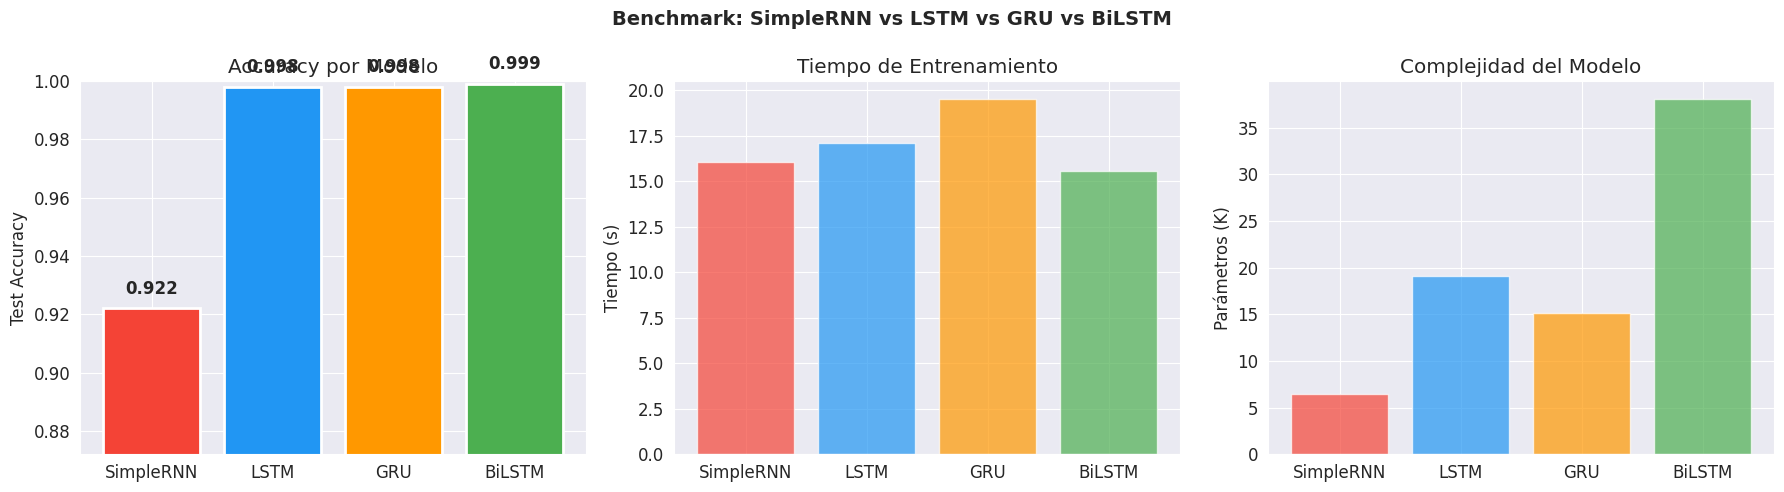


             Accuracy     Loss         Params       Tiempo (s)   Épocas  
---------------------------------------------------------------------------
SimpleRNN    0.9220       0.3058       6,469        16.1         12      
LSTM         0.9980       0.0051       19,141       17.1         18      
GRU          0.9980       0.0057       15,109       19.5         27      
BiLSTM       0.9990       0.0106       38,085       15.6         15      

🏆 Mejor modelo: BiLSTM (accuracy: 0.9990)


In [ ]:
# ============================================================
# 📊 Comparación de los 4 modelos
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

model_colors = [COLORS['rnn'], COLORS['lstm'], COLORS['gru'], COLORS['bilstm']]
accs = [results[mt]['accuracy'] for mt in model_types]
times = [results[mt]['time'] for mt in model_types]
params = [results[mt]['params'] for mt in model_types]

# Accuracy
bars = axes[0].bar(model_types, accs, color=model_colors, edgecolor='white', linewidth=2)
axes[0].set_ylabel('Test Accuracy')
axes[0].set_title('Accuracy por Modelo')
axes[0].set_ylim(min(accs) - 0.05, 1.0)
for bar, v in zip(bars, accs):
    axes[0].text(bar.get_x() + bar.get_width()/2, v + 0.005,
                 f'{v:.3f}', ha='center', fontweight='bold')

# Tiempo
axes[1].bar(model_types, times, color=model_colors, alpha=0.7, edgecolor='white')
axes[1].set_ylabel('Tiempo (s)')
axes[1].set_title('Tiempo de Entrenamiento')

# Parámetros
axes[2].bar(model_types, [p/1000 for p in params], color=model_colors,
            alpha=0.7, edgecolor='white')
axes[2].set_ylabel('Parámetros (K)')
axes[2].set_title('Complejidad del Modelo')

plt.suptitle('Benchmark: SimpleRNN vs LSTM vs GRU vs BiLSTM',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Tabla resumen
print('\n' + '=' * 75)
print(f'{"":<12} {"Accuracy":<12} {"Loss":<12} {"Params":<12} {"Tiempo (s)":<12} {"Épocas":<8}')
print('-' * 75)
for mt in model_types:
    r = results[mt]
    print(f'{mt:<12} {r["accuracy"]:<12.4f} {r["loss"]:<12.4f} '
          f'{r["params"]:<12,} {r["time"]:<12.1f} {r["epochs"]:<8}')
print('=' * 75)

best = max(results, key=lambda k: results[k]['accuracy'])
print(f'\n🏆 Mejor modelo: {best} (accuracy: {results[best]["accuracy"]:.4f})')

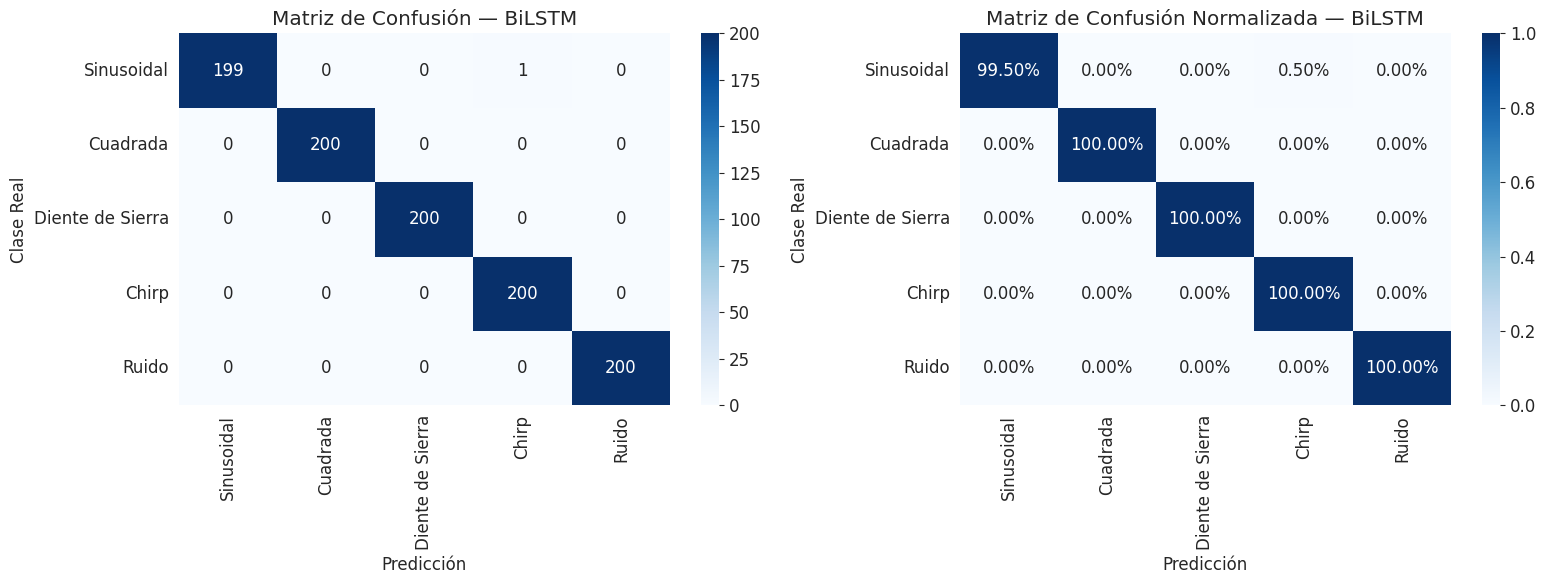


📋 Reporte de Clasificación — BiLSTM
                  precision    recall  f1-score   support

      Sinusoidal     1.0000    0.9950    0.9975       200
        Cuadrada     1.0000    1.0000    1.0000       200
Diente de Sierra     1.0000    1.0000    1.0000       200
           Chirp     0.9950    1.0000    0.9975       200
           Ruido     1.0000    1.0000    1.0000       200

        accuracy                         0.9990      1000
       macro avg     0.9990    0.9990    0.9990      1000
    weighted avg     0.9990    0.9990    0.9990      1000



In [ ]:
# ============================================================
# 🔍 Matriz de confusión del mejor modelo
# ============================================================
best_model = results[best]['model']
y_pred_cls = best_model.predict(X_test_sig, verbose=0)
y_pred_labels = np.argmax(y_pred_cls, axis=1)

cm = confusion_matrix(y_test_sig, y_pred_labels)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Heatmap
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names,
            ax=axes[0])
axes[0].set_xlabel('Predicción')
axes[0].set_ylabel('Clase Real')
axes[0].set_title(f'Matriz de Confusión — {best}')

# Heatmap normalizado
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
sns.heatmap(cm_norm, annot=True, fmt='.2%', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names,
            ax=axes[1])
axes[1].set_xlabel('Predicción')
axes[1].set_ylabel('Clase Real')
axes[1].set_title(f'Matriz de Confusión Normalizada — {best}')

plt.tight_layout()
plt.show()

# Reporte de clasificación
print(f'\n📋 Reporte de Clasificación — {best}')
print('=' * 65)
print(classification_report(y_test_sig, y_pred_labels,
                            target_names=class_names, digits=4))

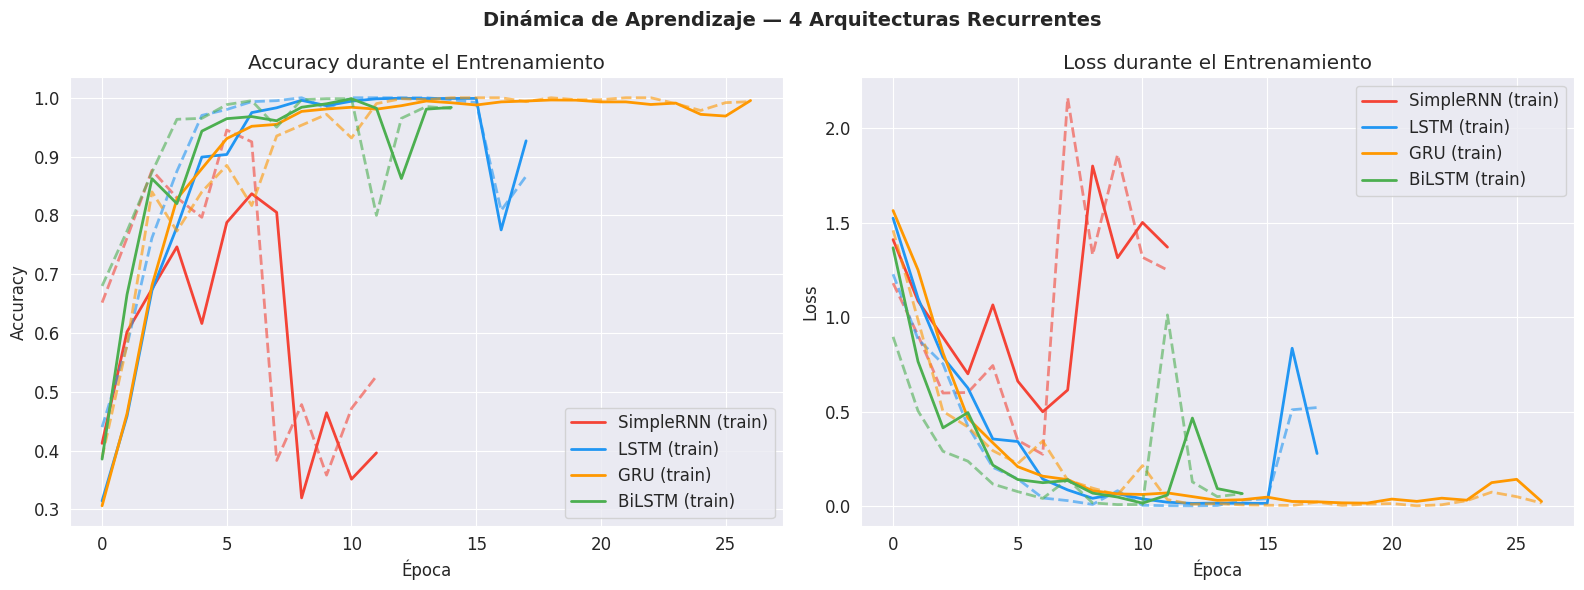

Observaciones:
  • SimpleRNN: Converge rápido pero a un techo más bajo
  • LSTM/GRU: Rendimiento similar, GRU ligeramente más rápido
  • BiLSTM: Mejor accuracy (lee en ambas direcciones)


In [ ]:
# ============================================================
# 📈 Curvas de aprendizaje de los 4 modelos
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for mt, color in zip(model_types, model_colors):
    h = results[mt]['history']
    axes[0].plot(h.history['accuracy'], color=color,
                 linewidth=2, label=f'{mt} (train)')
    axes[0].plot(h.history['val_accuracy'], color=color,
                 linewidth=2, linestyle='--', alpha=0.6)

axes[0].set_xlabel('Época')
axes[0].set_ylabel('Accuracy')
axes[0].set_title('Accuracy durante el Entrenamiento')
axes[0].legend(loc='lower right')

for mt, color in zip(model_types, model_colors):
    h = results[mt]['history']
    axes[1].plot(h.history['loss'], color=color,
                 linewidth=2, label=f'{mt} (train)')
    axes[1].plot(h.history['val_loss'], color=color,
                 linewidth=2, linestyle='--', alpha=0.6)

axes[1].set_xlabel('Época')
axes[1].set_ylabel('Loss')
axes[1].set_title('Loss durante el Entrenamiento')
axes[1].legend(loc='upper right')

plt.suptitle('Dinámica de Aprendizaje — 4 Arquitecturas Recurrentes',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print('Observaciones:')
print('  • SimpleRNN: Converge rápido pero a un techo más bajo')
print('  • LSTM/GRU: Rendimiento similar, GRU ligeramente más rápido')
print('  • BiLSTM: Mejor accuracy (lee en ambas direcciones)')

---

## ✅ Checklist de Verificación — Series de Tiempo con Deep Learning

| # | Verificación | Estado |
|---|---|---|
| 1 | Split cronológico (nunca aleatorio para forecasting) | ✅ |
| 2 | Normalización con `fit` solo en datos de entrenamiento | ✅ |
| 3 | Ventanas deslizantes con función `create_sequences` reproducible | ✅ |
| 4 | Shapes correctos: `(samples, timesteps, features)` | ✅ |
| 5 | Baseline naive calculado antes de evaluar el modelo | ✅ |
| 6 | EarlyStopping + ReduceLROnPlateau para evitar sobreajuste | ✅ |
| 7 | Métricas apropiadas: MAE/RMSE para forecasting | ✅ |
| 8 | Dropout entre capas recurrentes apiladas | ✅ |
| 9 | Desnormalización antes de calcular métricas interpretables | ✅ |
| 10 | Visualización de predicciones vs valores reales | ✅ |
| 11 | Mismos hiperparámetros para LSTM y GRU (comparación justa) | ✅ |
| 12 | Dos datasets de naturaleza distinta (periódico vs ruidoso) | ✅ |

## 📋 Resumen de Resultados

| Dataset | Tarea | Arquitectura | Variables | Resultado Clave |
|---|---|---|---|---|
| ☀️ Solar (Kaggle) | Forecasting multivariado, 15 min | LSTM vs GRU stacked | Potencia AC + clima (4 vars) | _(completa con tus resultados)_ |
| 🔶 Cobre (COMEX) | Forecasting multivariado, diario | LSTM vs GRU stacked | Cierre + OHLV (5 vars) | _(completa con tus resultados)_ |

**Lecciones transversales:**
- La preparación de datos (split, normalización, ventanas) importa más que la arquitectura
- GRU es un excelente punto de partida por su balance rendimiento/eficiencia
- El baseline naive es un punto de comparación obligatorio: en series ruidosas (como un commodity) es muy difícil de superar
- Las series periódicas (solar) son mucho más predecibles que las series de precios